# Arrival timing and within-pair synchrony

## The measure

For each finger the chord requires to move:

> **arrival(k)** = the time, relative to `RT`, at which finger k *last* entered its target
> zone and stayed inside it through to chord acquisition (`RT + ET`).

"Last" rather than "first" because `ET` marks the acquisition whose hold succeeded — a
finger may dip in and out on the way, and what matters is when it settled. Times are
relative to `RT`, so this describes the *relative* timing of the fingers rather than how
fast the trial was overall.

> **within latency** = |arrival(k₁) − arrival(k₂)| for the two fingers of one component.

The trained components occupy fixed finger slots: one on thumb+index, one on ring+pinky. A
4-finger chord may contain both of them, one, or neither. **The within latency is only
meaningful for a pair that is actually a trained component** — for an untrained pair the
two fingers were never practised together, so there is no learned synchrony to look for.
Those pairs get arrival markers in the figures but no bracket.

The question this asks: when a trained component is embedded in a larger chord, does it
keep the synchrony it acquired during training?

## Why there is no between-pair measure here

An earlier version also measured the gap *between* the two pairs. That measure is
confounded: it is bounded above by the duration of the trial, so it must shrink when `ET`
shrinks, and `ET` drops sharply from Test 1 to Test 2 for every chord. A decrease in it
therefore says nothing specific about composition. It has been removed.

The same concern applies in weaker form to the within latency, which is why the untrained
pairs matter — in a chord like `12921` one pair is trained and the other is not, measured
on the same trials with the same `ET`. That contrast is internally controlled.

Reads `analysis/s<sn>.csv` and `analysis/s<sn>_mov.pkl`.

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

SN = 101
SEED = 1517            # <<< int for reproducible trial picks, None for fresh ones

from utils.design import TEST1_BLOCKS, TEST2_BLOCKS, TRAIN_BLOCKS, TRAIN_EARLY, TRAIN_LATE
from utils.examples import mark_unsuccessful, panel_title, sample, session_label

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ROOT / "figures" / f"s{SN}"
EX_DIR = FIG_DIR / "example_trials"
EX_DIR.mkdir(parents=True, exist_ok=True)
WL_DIR = FIG_DIR / "within_latency"
WL_DIR.mkdir(parents=True, exist_ok=True)

WAIT_EXEC = 3
PRE_BLOCKS, POST_BLOCKS = TEST1_BLOCKS, TEST2_BLOCKS       # day 1 Test 1, day 3 Test 2
FINGERS = ["thumb", "index", "middle", "ring", "pinky"]
STATE_OF = {"1": "ext", "2": "flex", "9": "rel"}
PAIR_A, PAIR_B = (0, 1), (3, 4)                            # the two component finger slots

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})
PAL = dict(zip(FINGERS, sns.color_palette("colorblind", 5)))

df = pd.read_csv(ANALYSIS_DIR / f"s{SN}.csv")
mov = pd.read_pickle(ANALYSIS_DIR / f"s{SN}_mov.pkl")
REC = {(r.BN, r.TN): r for r in mov.itertuples()}
rng = np.random.default_rng(SEED)

# which chords were trained, and which finger slot each occupies
TRAINED = sorted(df.loc[df.BN.isin(TRAIN_BLOCKS), "chordID"].unique().tolist())
COMPONENT = {tuple(i for i, d in enumerate(str(c)) if d != "9"): c for c in TRAINED}
TESTED = sorted(df.loc[df.BN.isin(PRE_BLOCKS), "chordID"].unique().tolist())
print("trained components:", {FINGERS[k[0]] + "+" + FINGERS[k[1]]: v for k, v in COMPONENT.items()})
print("tested 4-finger chords:", TESTED)

trained components: {'thumb+index': 12999, 'ring+pinky': 99912}
tested 4-finger chords: [12912, 12921, 21912, 21921]


## Arrival times for every trial

`within_A` / `within_B` are the two pairs' latencies; `A_trained` / `B_trained` say whether
that pair is one of the trained components for this subject.

In [2]:
rows = []
for _, tr in df[df.trialPoint == 1].iterrows():
    rec = REC[(int(tr.BN), int(tr.TN))]
    ex = np.where(rec.state == WAIT_EXEC)[0]
    if not len(ex):
        continue
    t0 = rec.t[ex[0]]
    acq = t0 + tr.RT + tr.ET
    F = rec.force
    chord = str(int(tr.chordID))

    arrival, ok = {}, True
    for k, d in enumerate(chord):
        if d == "9":
            continue
        inzone = ((F[:, k] >= tr.extBotThresh) & (F[:, k] <= tr.extTopThresh)) if d == "1" \
            else ((F[:, k] >= tr.flexTopThresh) & (F[:, k] <= tr.flexBotThresh))
        inzone = inzone & (rec.state == WAIT_EXEC) & (rec.t <= acq + 1)
        idx = np.where(inzone)[0]
        if not len(idx):
            ok = False
            break
        j = idx[-1]
        while j - 1 >= 0 and inzone[j - 1]:
            j -= 1
        arrival[k] = rec.t[j] - t0 - tr.RT
    if not ok:
        continue

    r = dict(sn=int(tr.sn), day=int(tr.day), BN=int(tr.BN), TN=int(tr.TN),
             chordID=int(tr.chordID), n_active=len(arrival), ET=tr.ET, MD=tr.MD)
    for k, v in arrival.items():
        r[f"arr_{FINGERS[k]}"] = v
    for pair, tag in [(PAIR_A, "A"), (PAIR_B, "B")]:
        if all(k in arrival for k in pair):
            r[f"within_{tag}"] = abs(arrival[pair[0]] - arrival[pair[1]])
            # this pair is a trained component only if the required digits match it
            r[f"{tag}_trained"] = (pair in COMPONENT and
                                   all(chord[i] == str(COMPONENT[pair])[i] for i in pair))
        else:
            r[f"within_{tag}"], r[f"{tag}_trained"] = np.nan, False
    rows.append(r)

arr = pd.DataFrame(rows)
arr["test"] = np.where(arr.BN.isin(PRE_BLOCKS), "Test 1 (day 1)",
                       np.where(arr.BN.isin(POST_BLOCKS), "Test 2 (day 3)", "training"))
print(f"{len(arr)} of {int((df.trialPoint == 1).sum())} correct trials have a full set of arrivals")
arr[["chordID", "test", "within_A", "A_trained", "within_B", "B_trained"]].head()

750 of 821 correct trials have a full set of arrivals


,chordID,test,within_A,A_trained,within_B,B_trained
0,12921,Test 1 (day 1),1556.0,True,746.0,False
1,12921,Test 1 (day 1),82.0,True,156.0,False
2,12921,Test 1 (day 1),38.0,True,468.0,False
3,12912,Test 1 (day 1),374.0,True,1696.0,True
4,12912,Test 1 (day 1),2306.0,True,1376.0,True


## Example trials

One figure per chord, day 1 above and day 3 below, saved into `figures/s<sn>/example_trials/`.
Dots mark each finger's arrival. A bracket with a `within` label is drawn **only** for a
pair that is a trained component; untrained pairs get their arrival dots and nothing else.

Trials are picked at random, spread evenly across the session's blocks. Change `SEED` for a
different draw.

Correct trials are drawn first. If a session has fewer correct trials than rows (e.g. a
chord the subject could not produce at all in Test 1), the rest are filled with
unsuccessful trials, tinted red and tagged `UNSUCCESSFUL` with how they failed, and the
session header says how many of the shown trials failed. Plan errors are never used.
Unsuccessful trials run to the 10 s time-out, so each session has its own time axis.

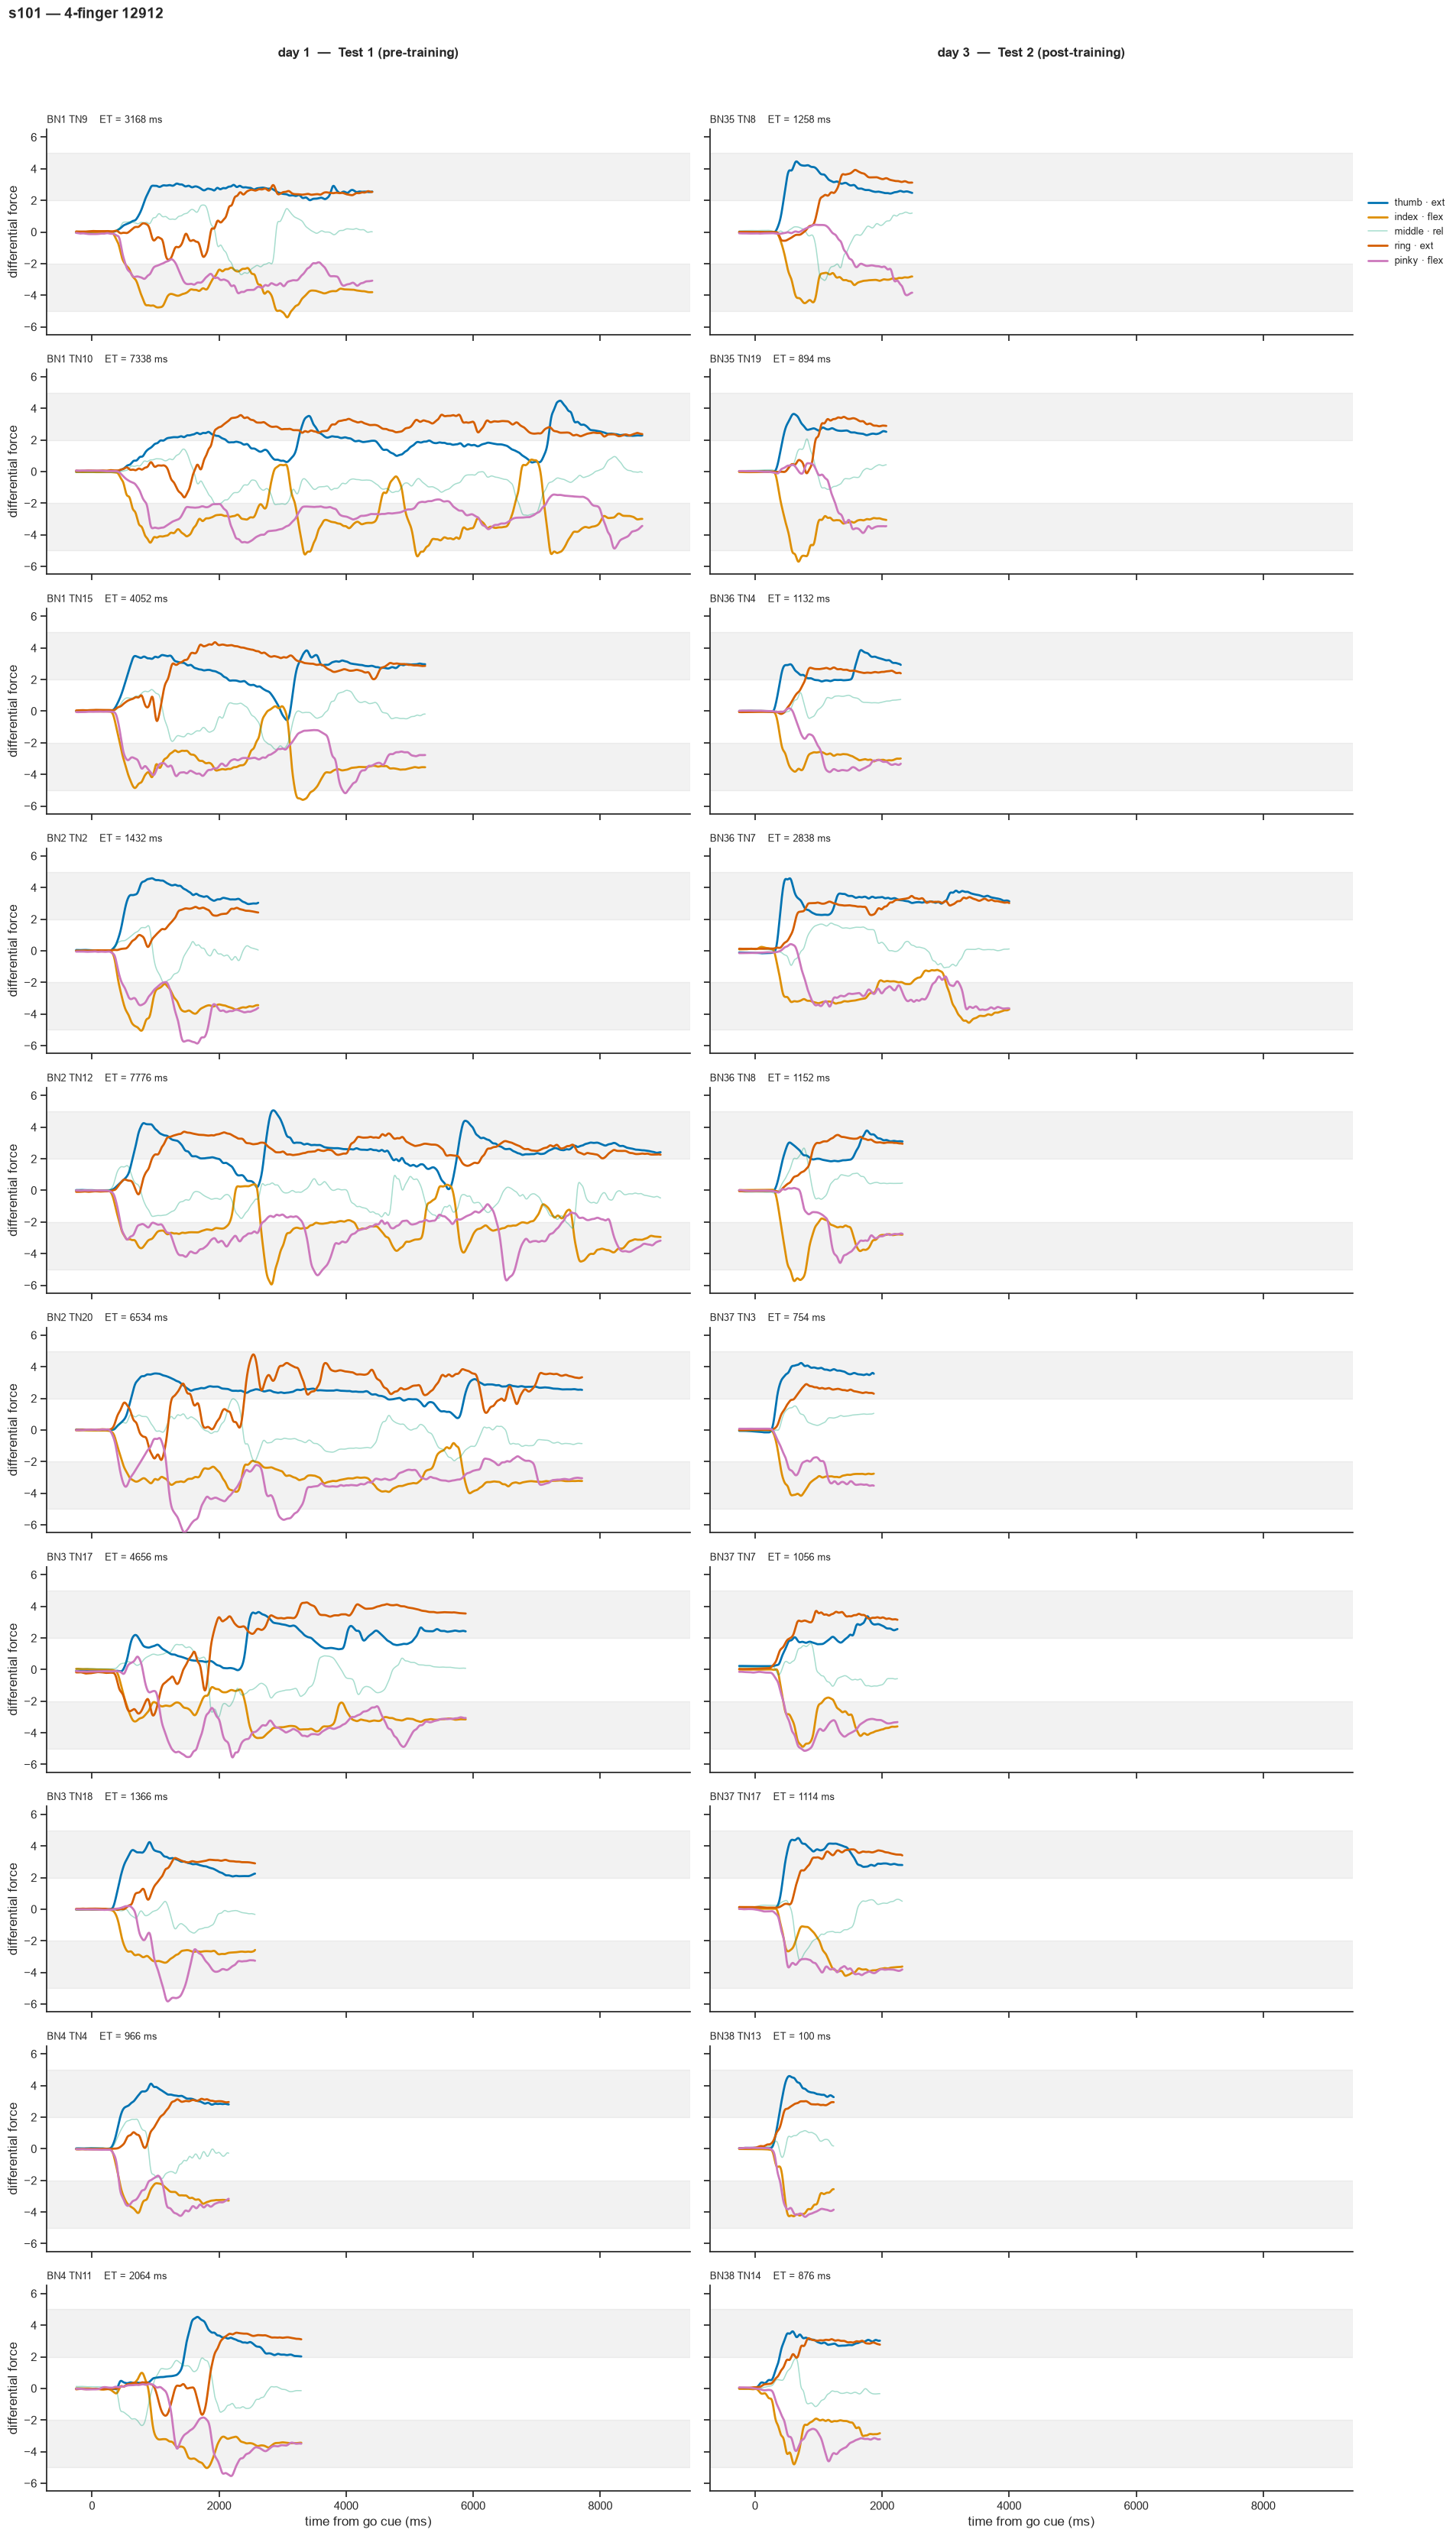

wrote figures/s101/example_trials/chord_12912.png


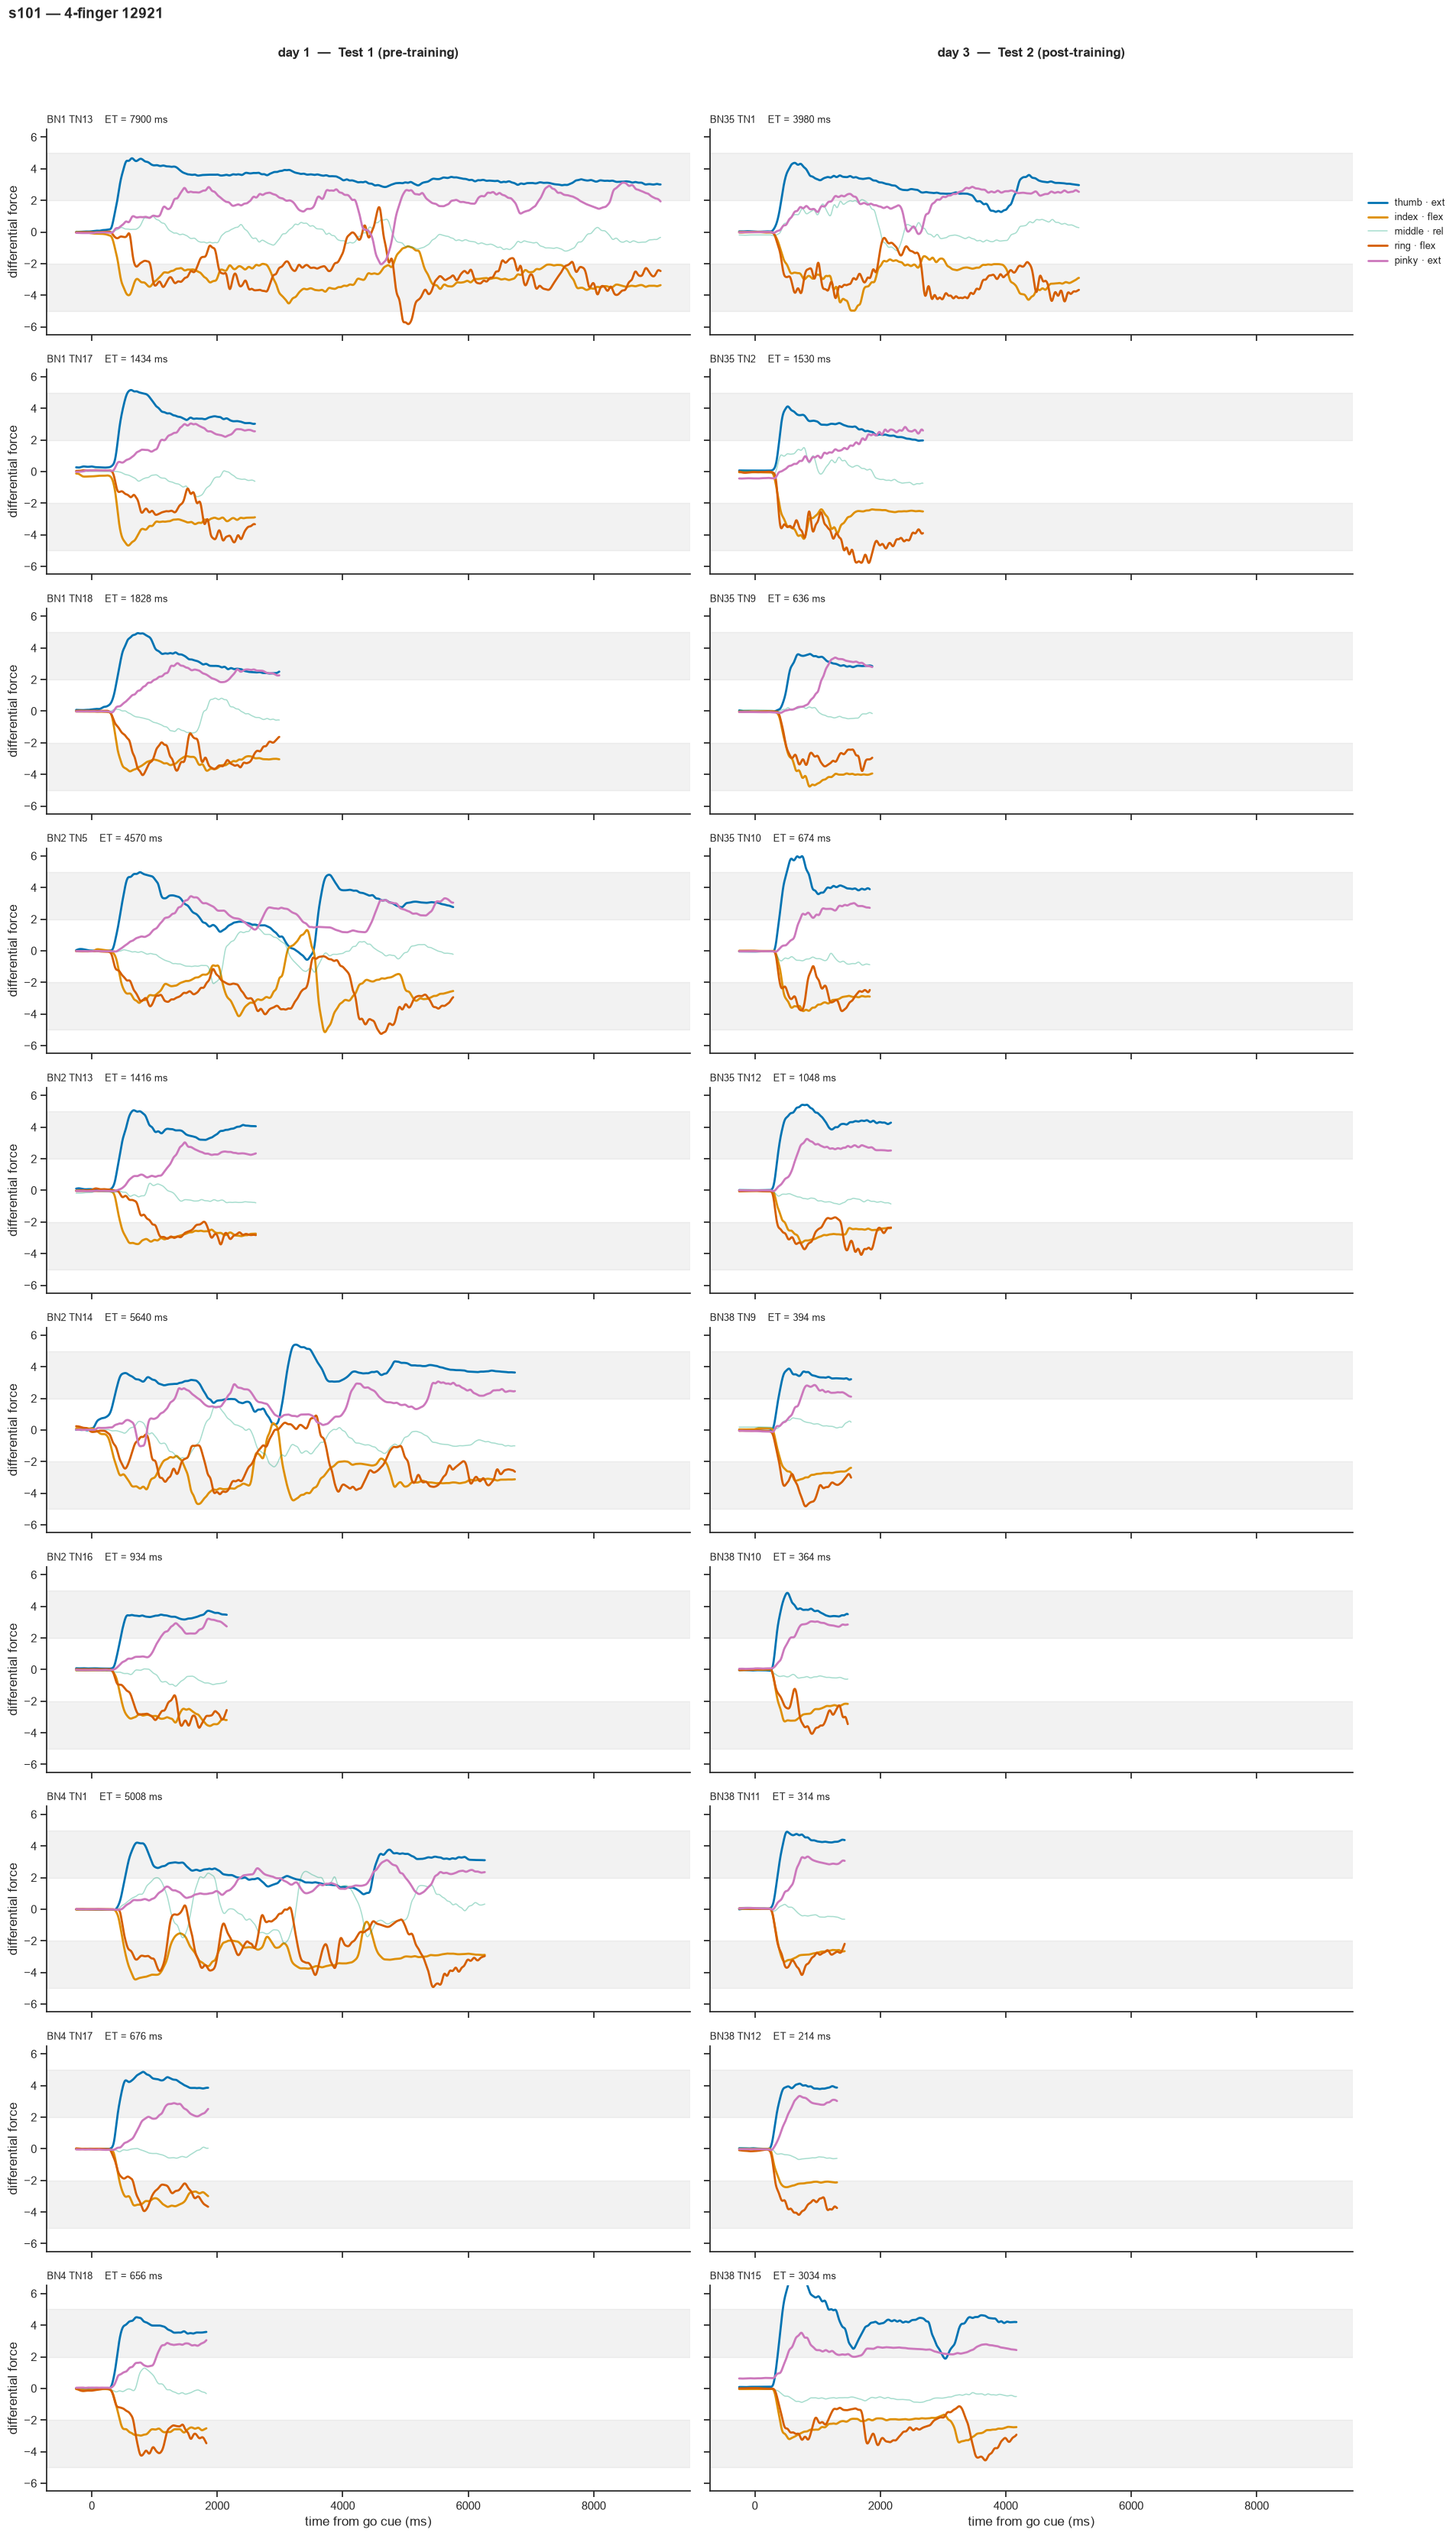

wrote figures/s101/example_trials/chord_12921.png


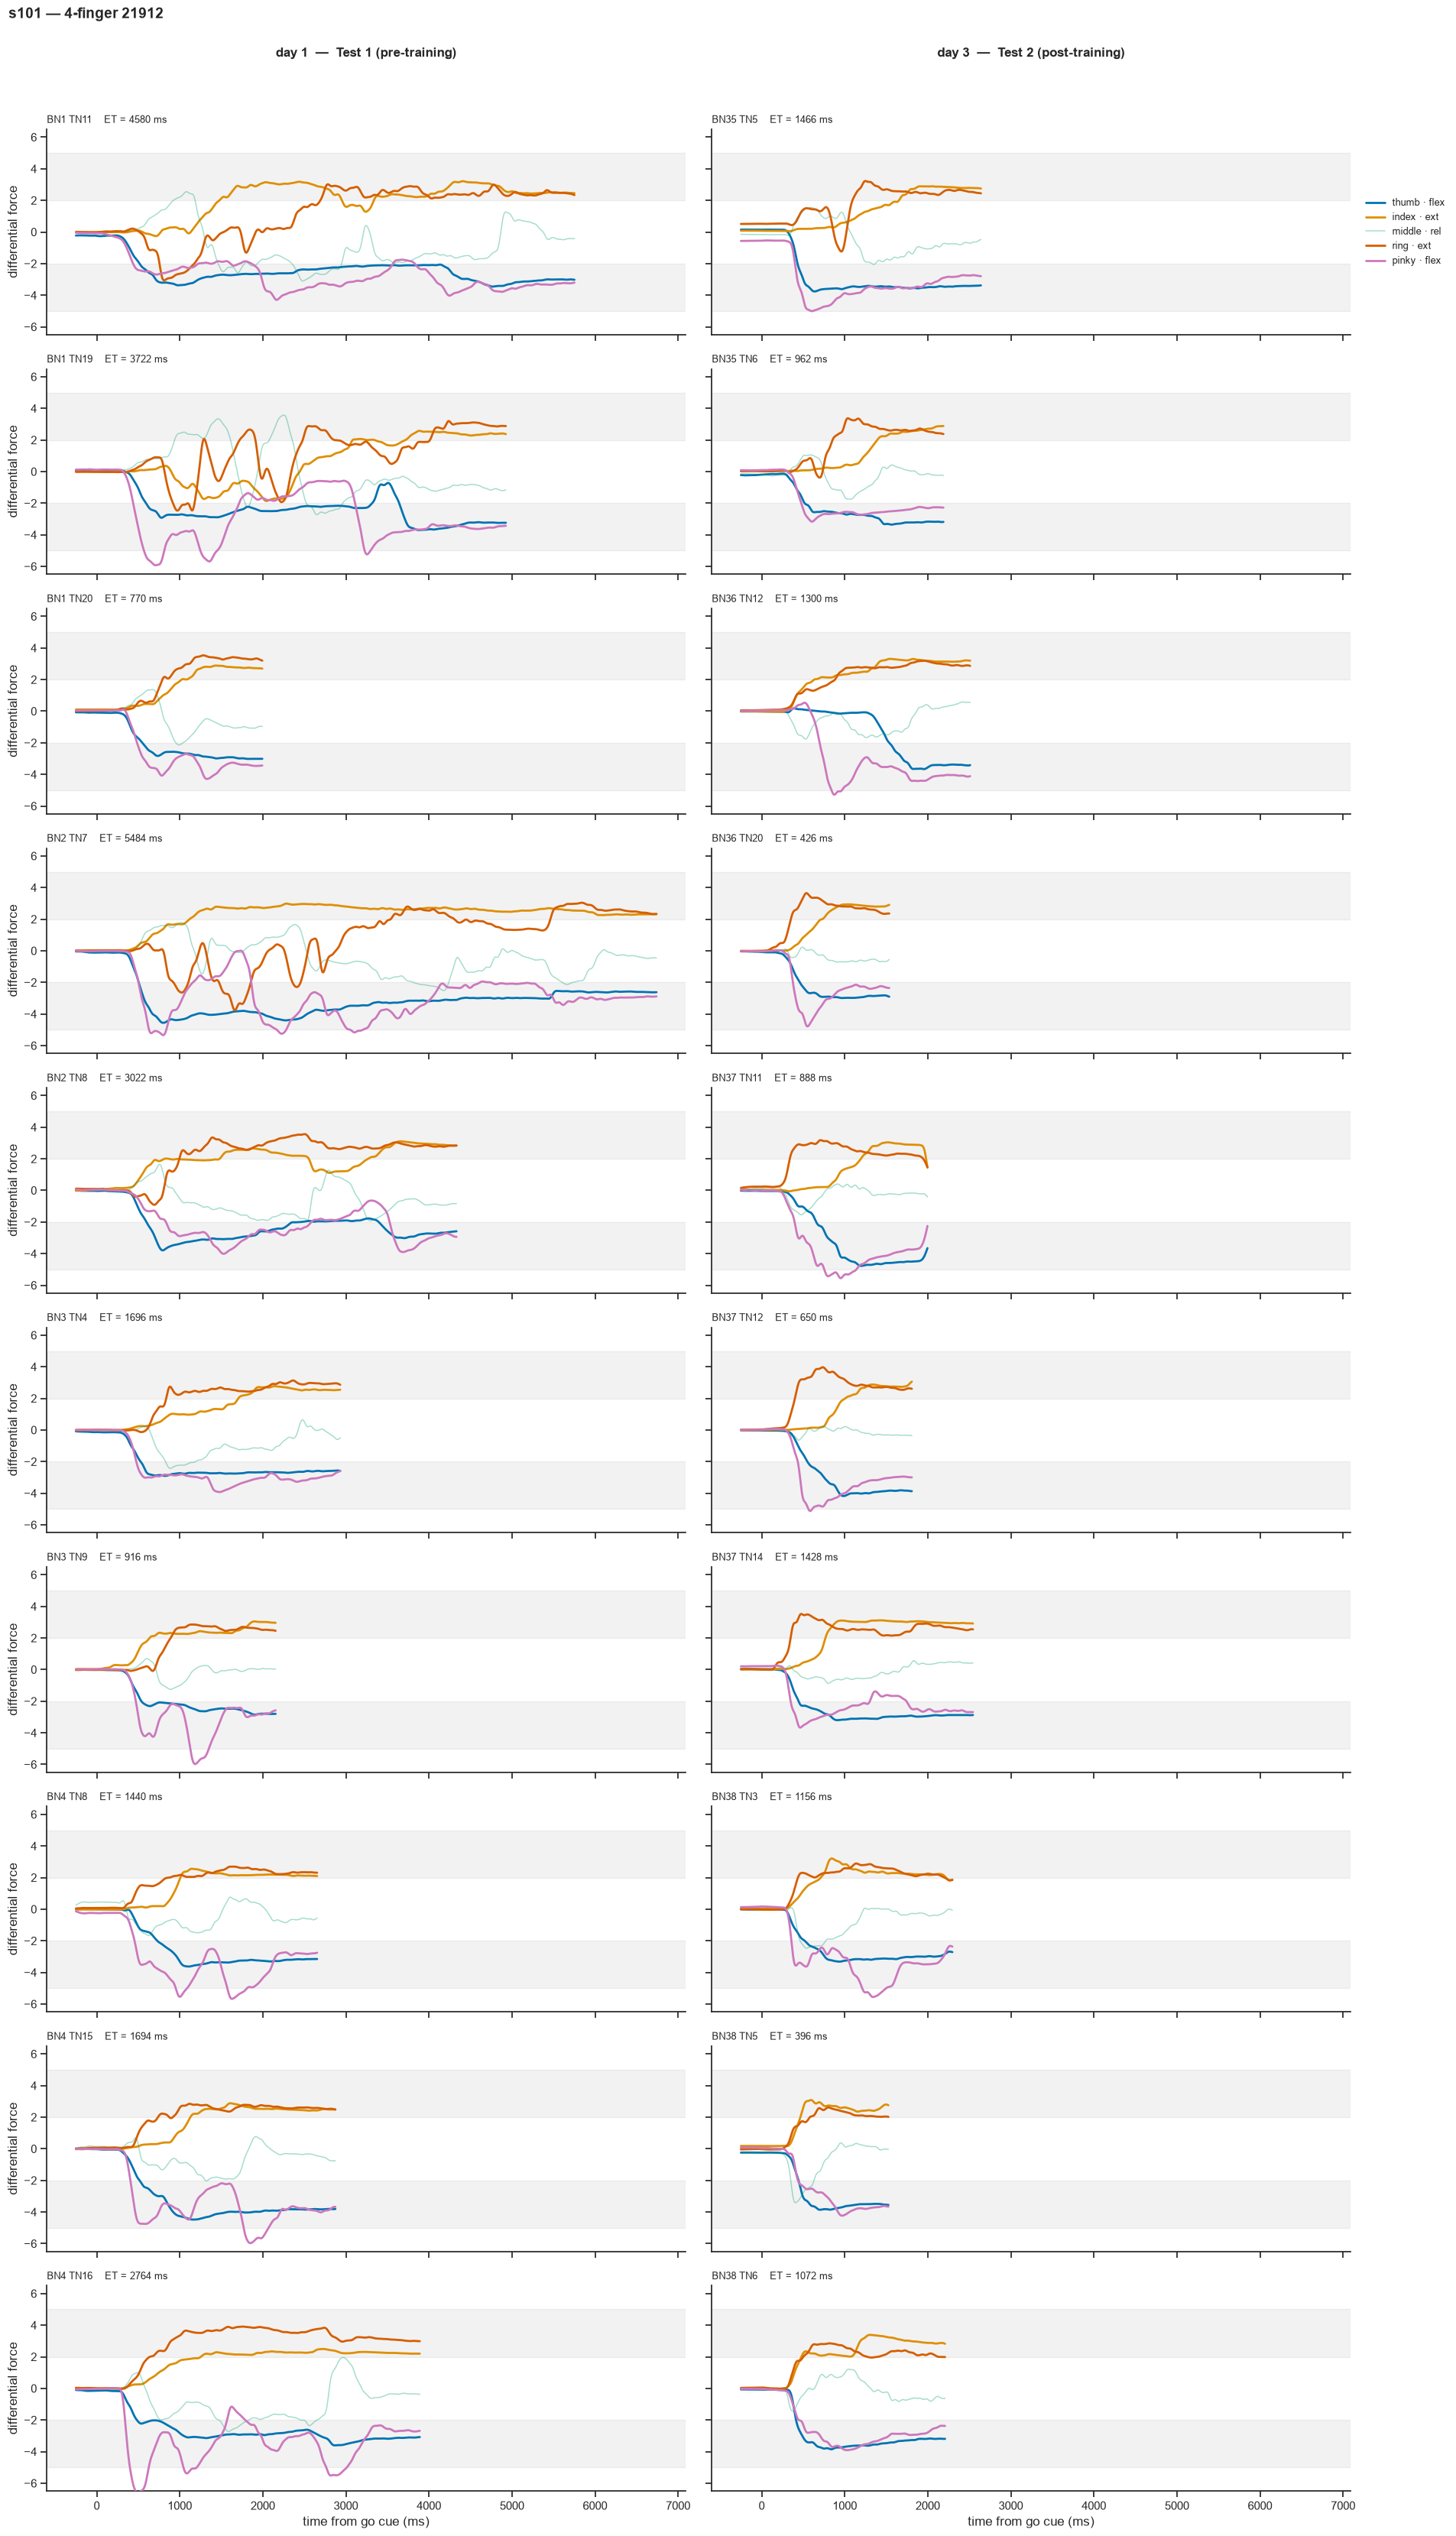

wrote figures/s101/example_trials/chord_21912.png


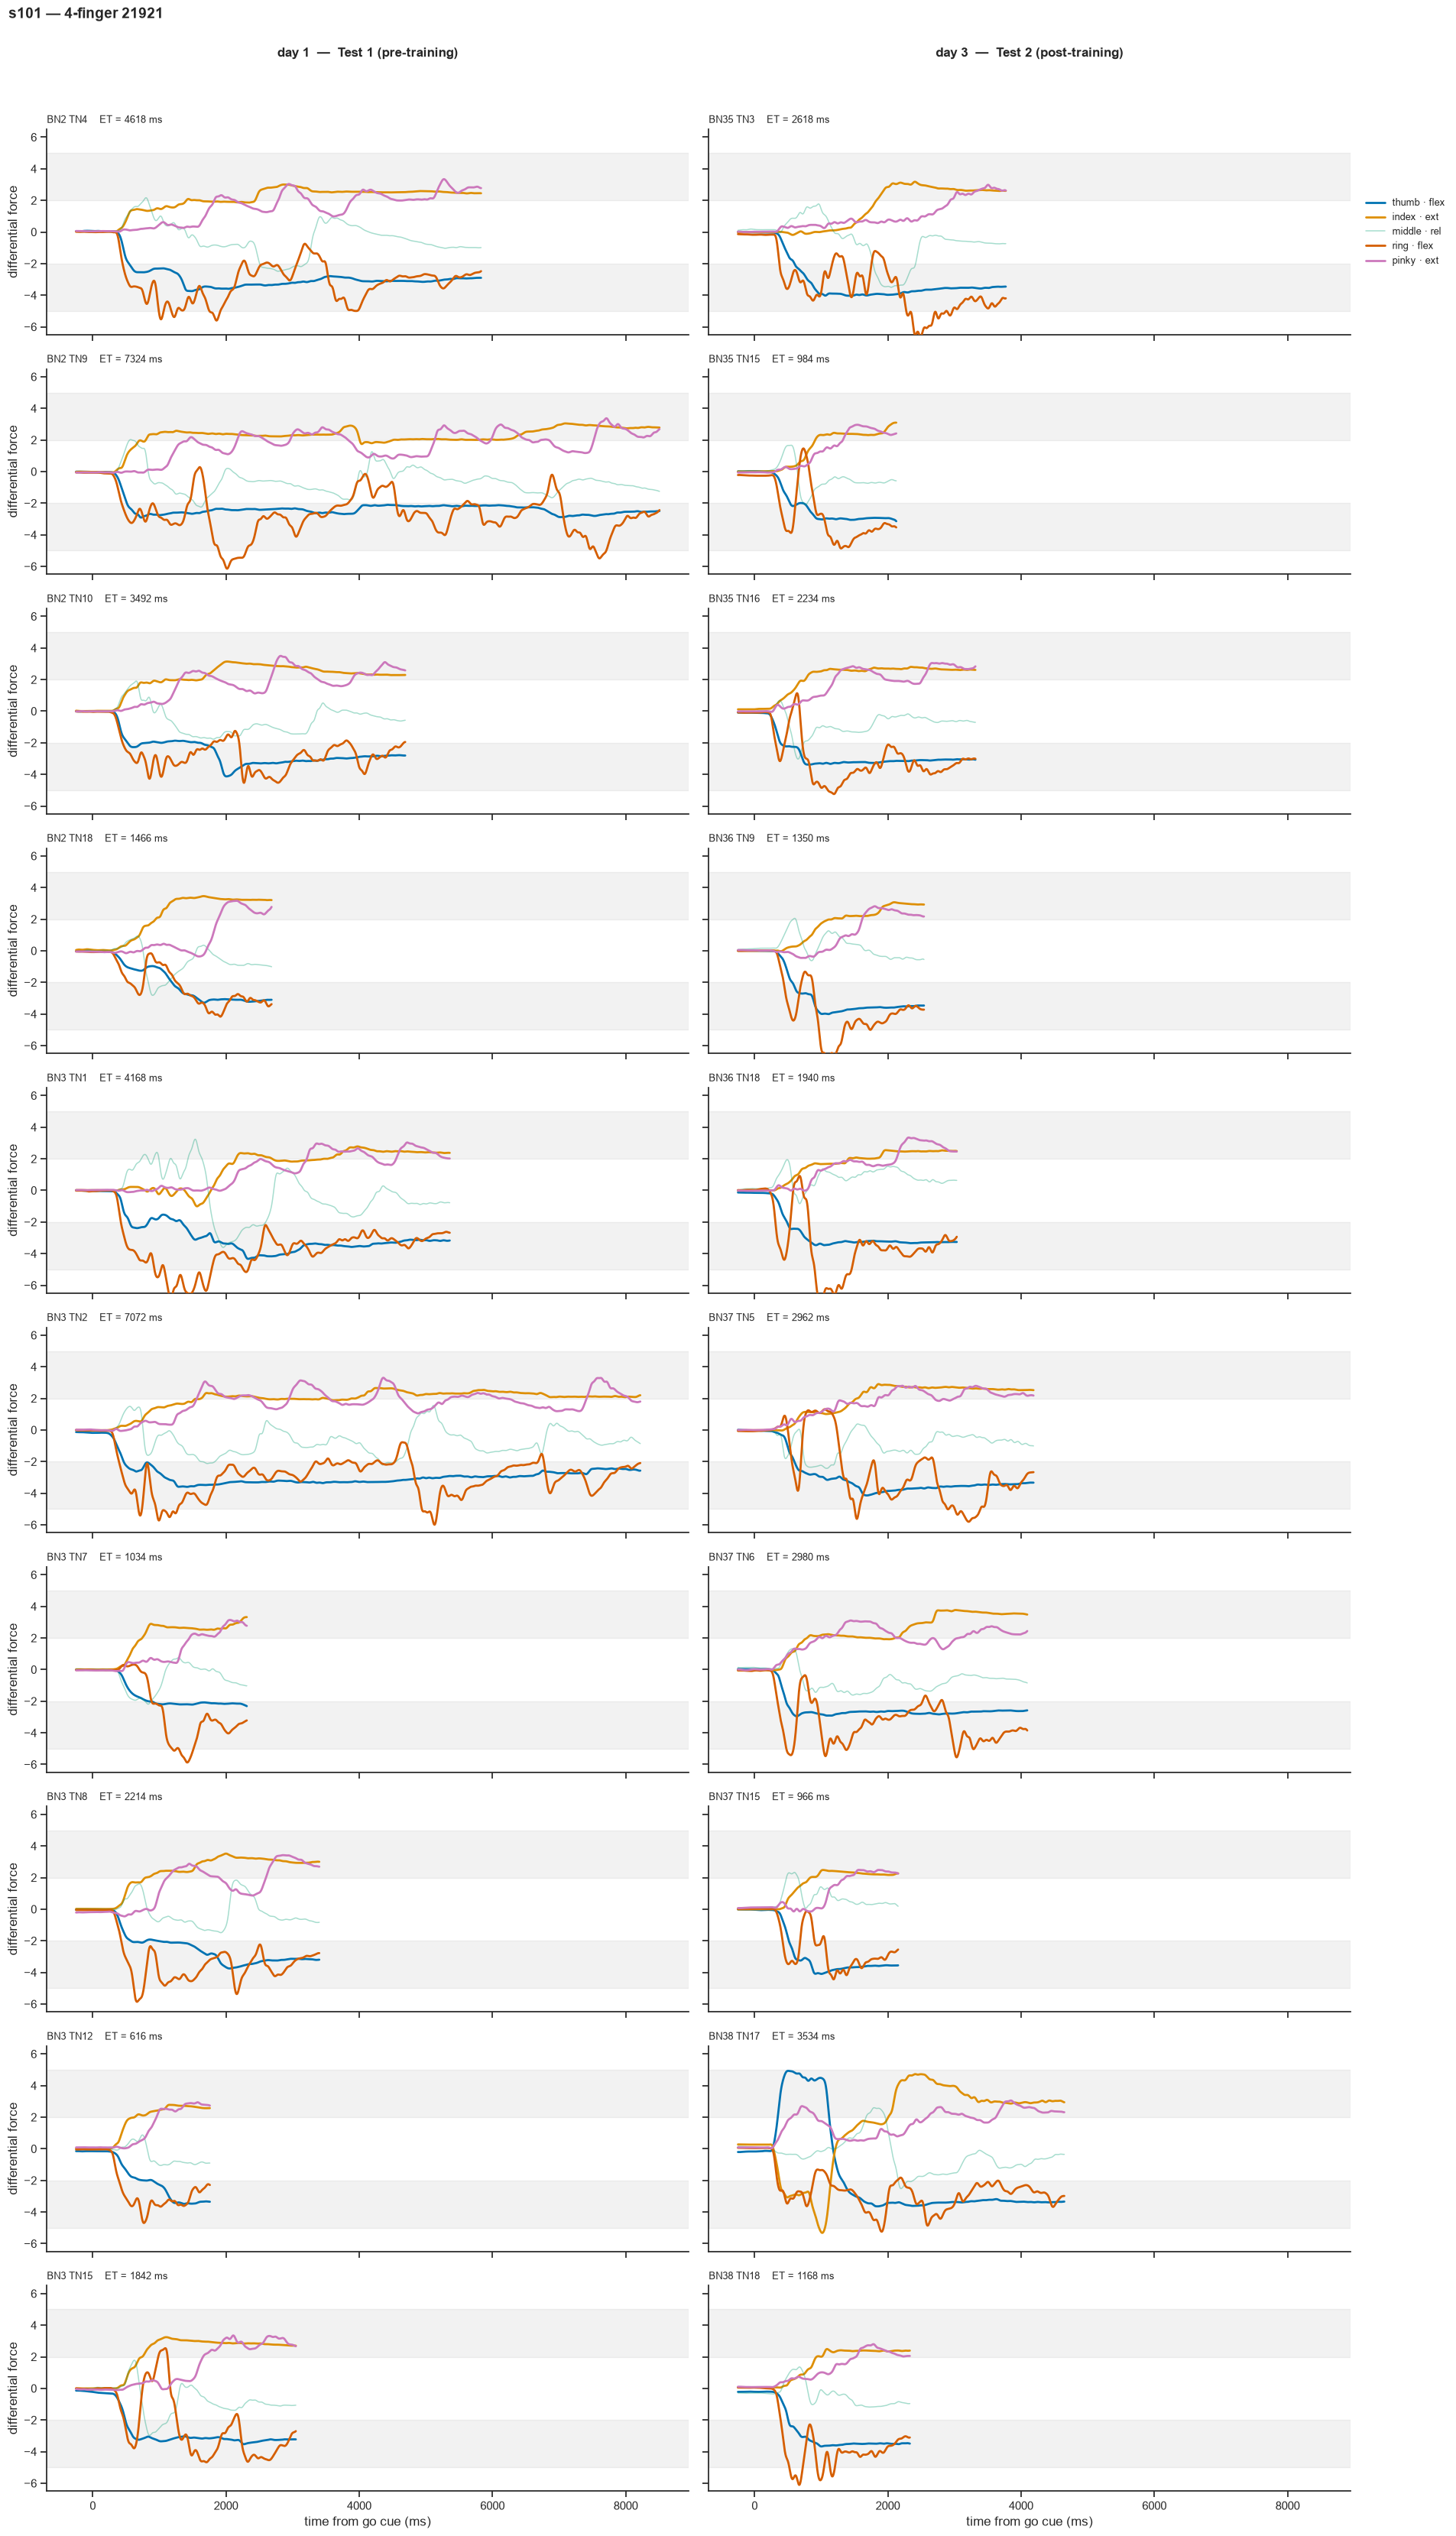

wrote figures/s101/example_trials/chord_21921.png


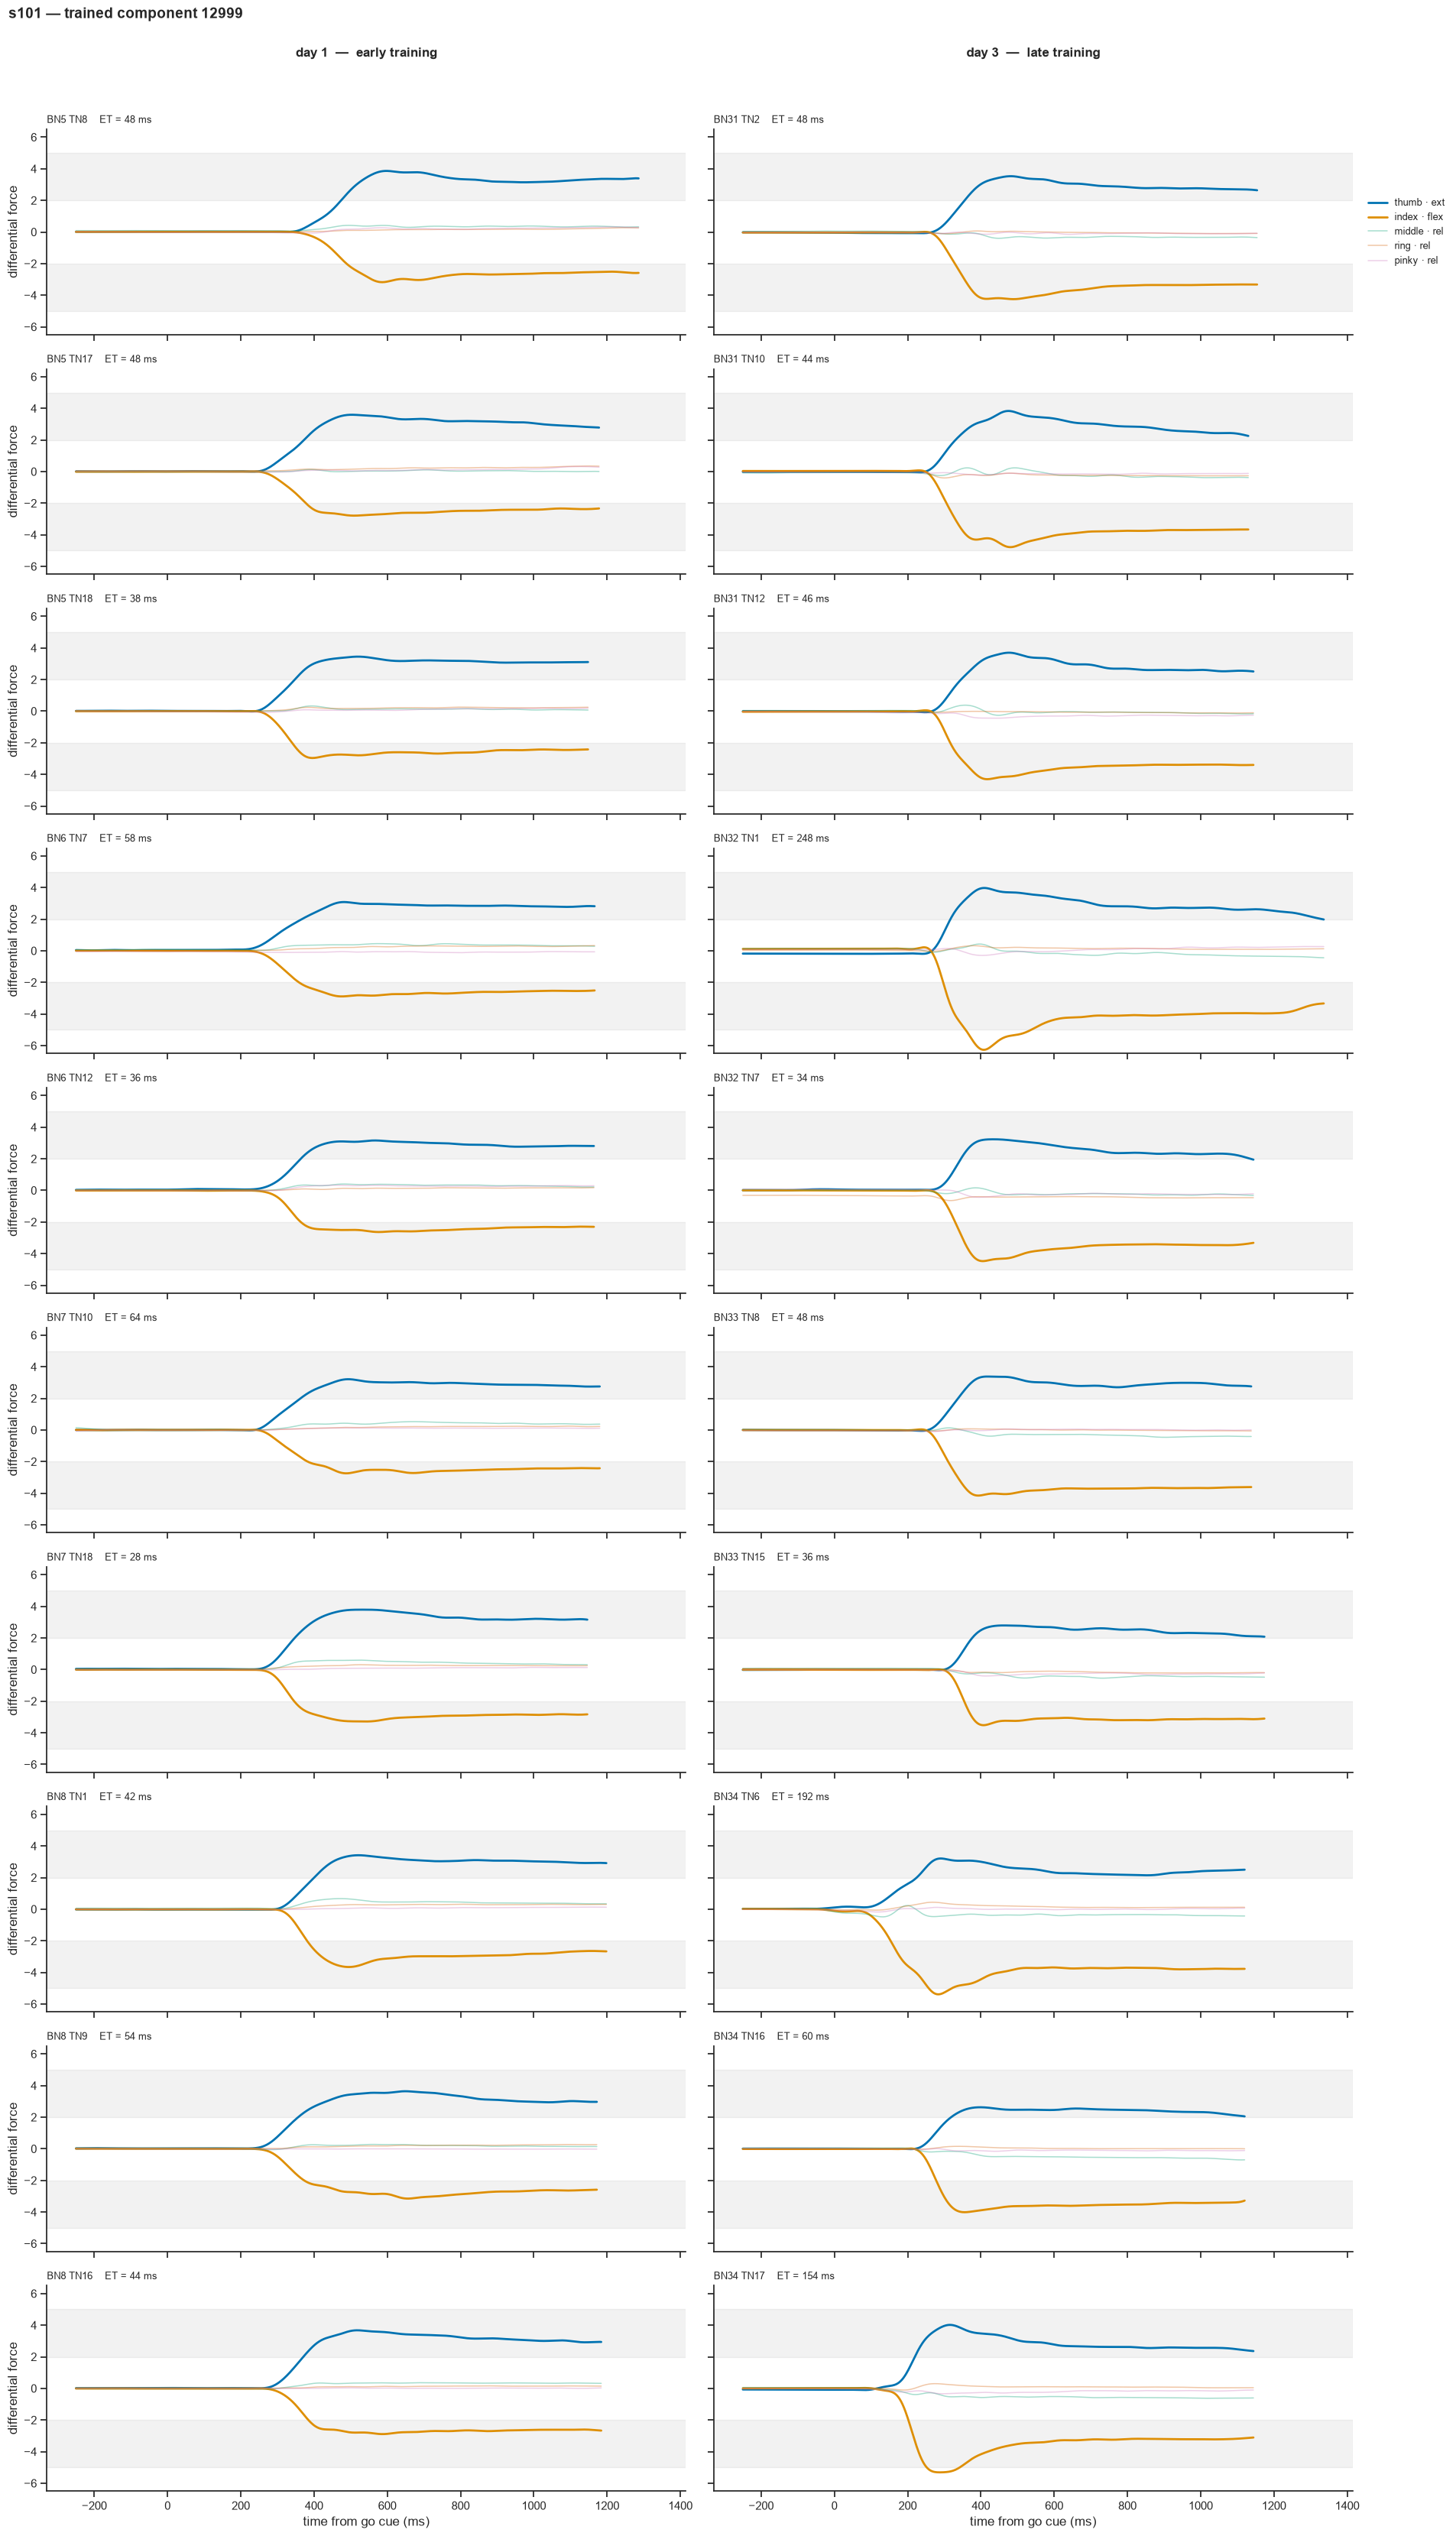

wrote figures/s101/example_trials/component_12999.png


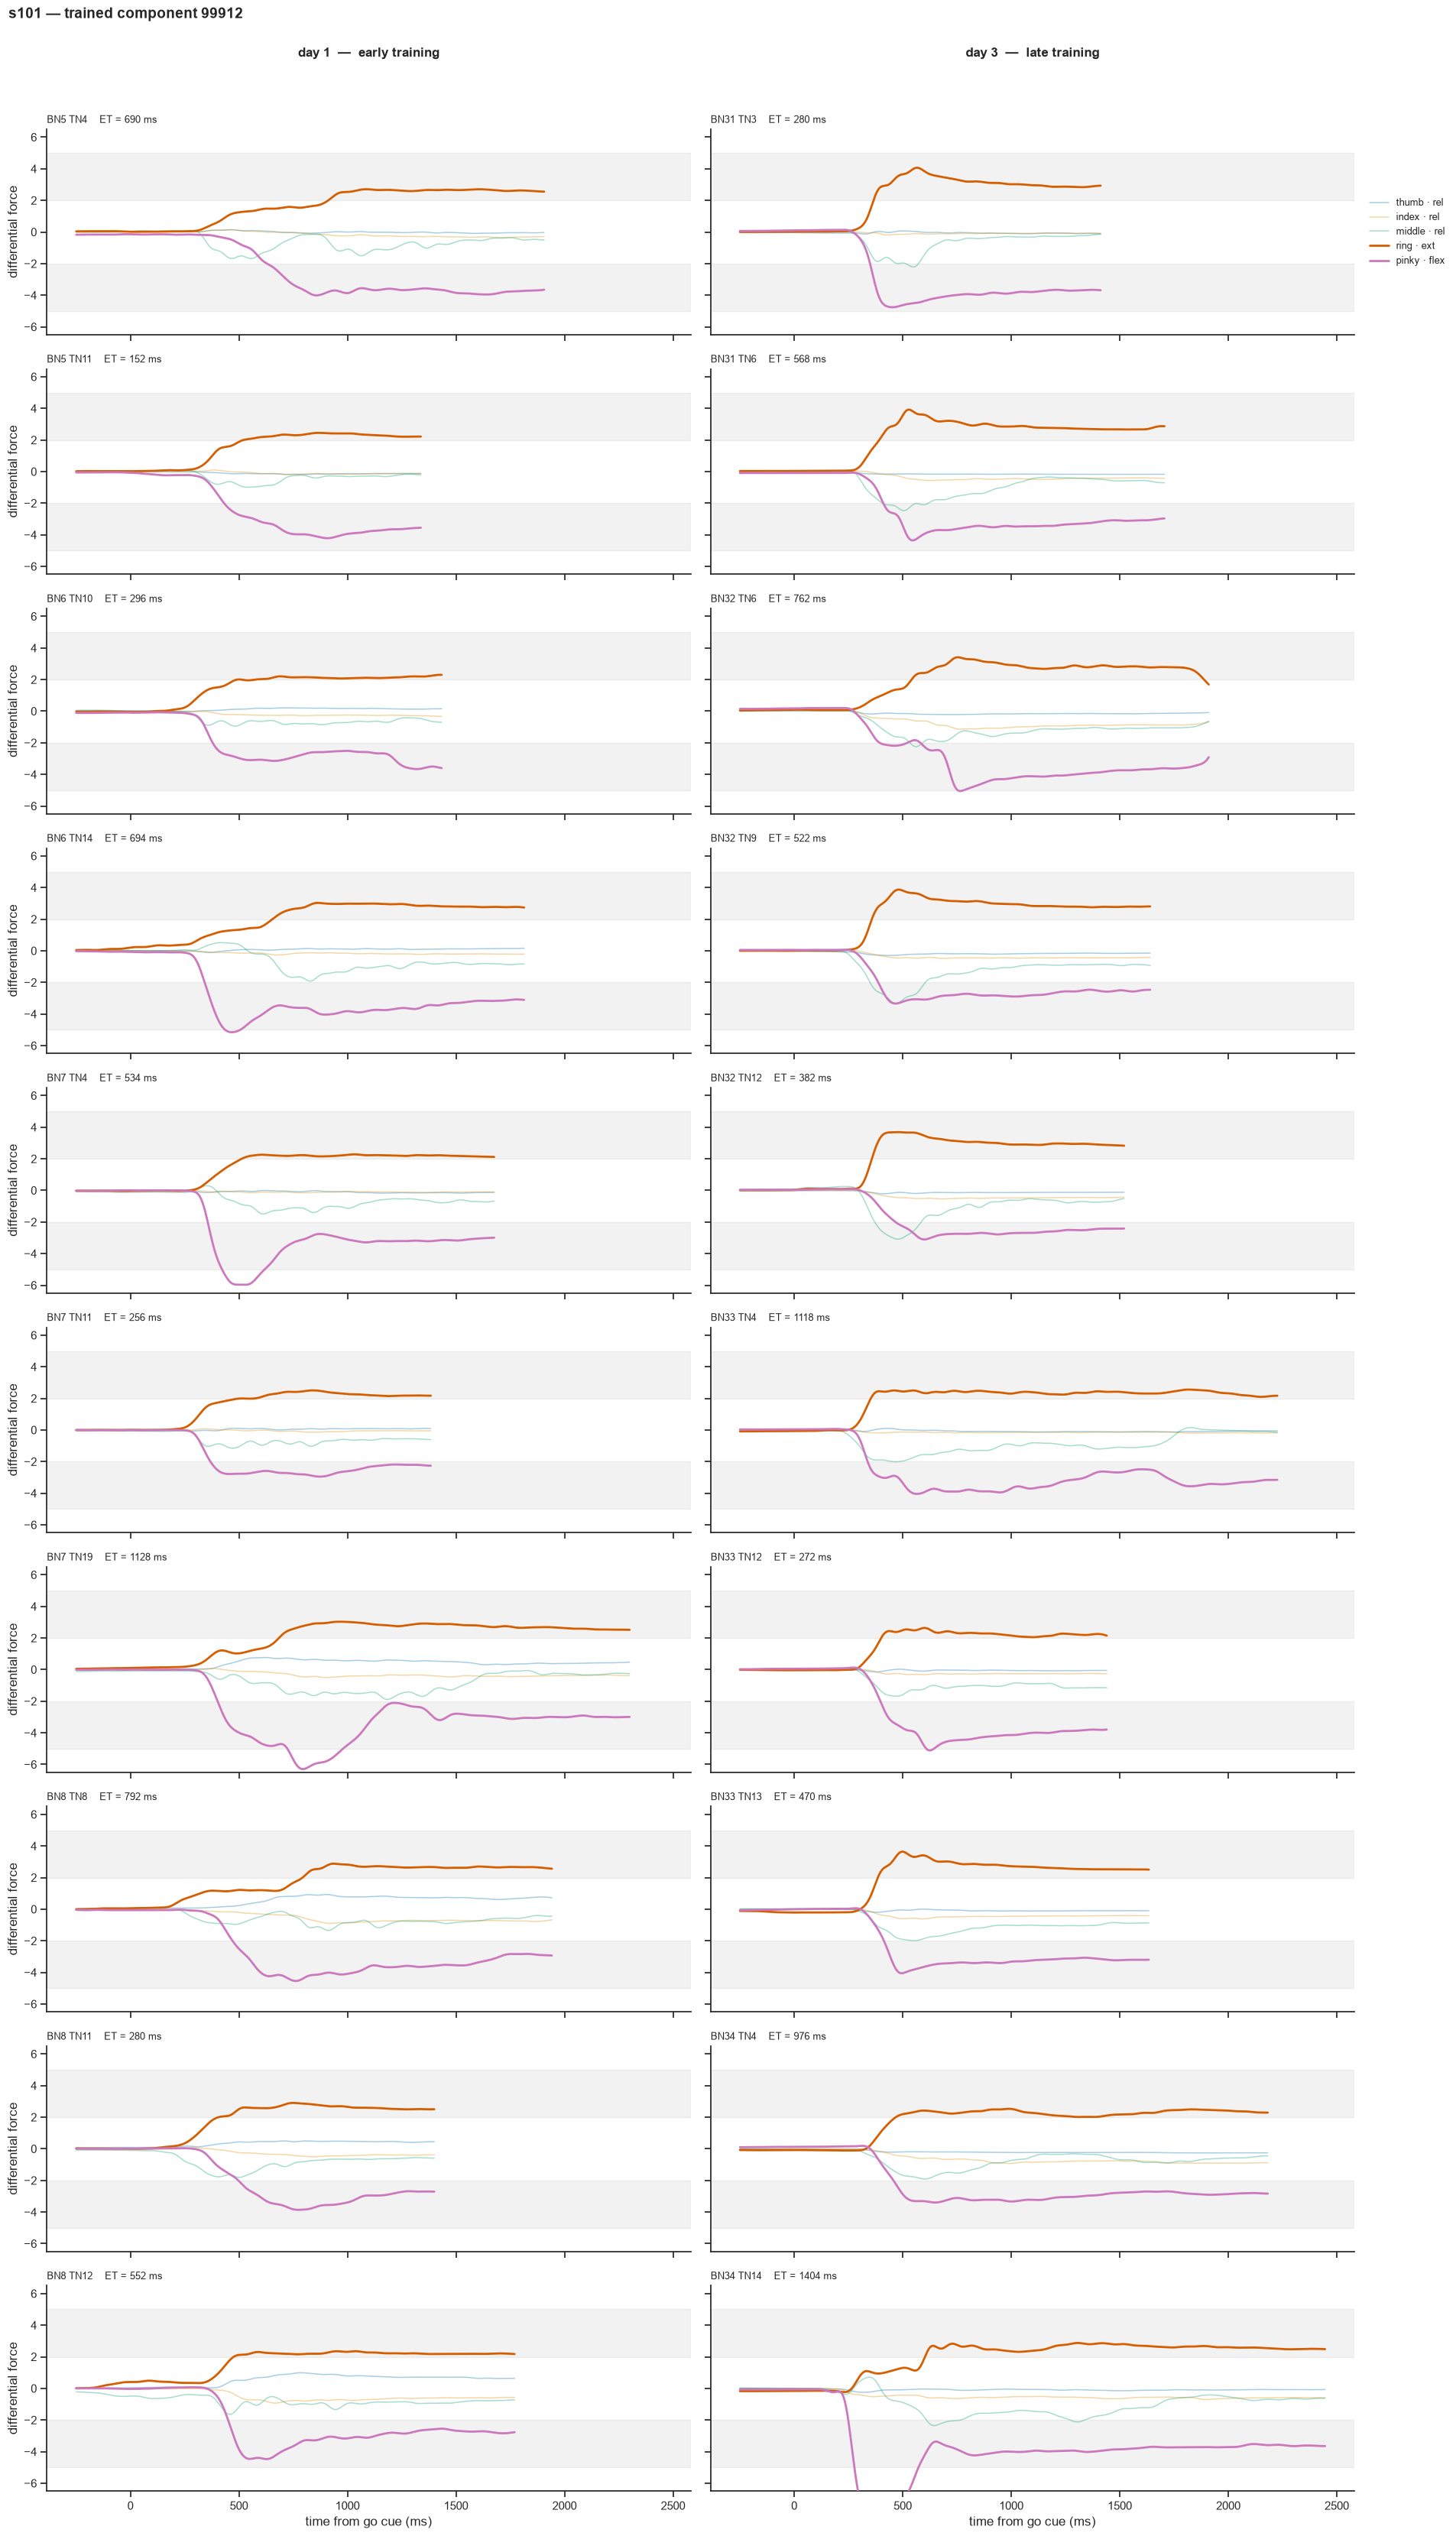

wrote figures/s101/example_trials/component_99912.png


In [3]:
def draw(ax, tr, row):
    """One trial: force traces, arrival dots, and within brackets on trained pairs only."""
    rec = REC[(int(row.BN), int(row.TN))]
    t0 = rec.t[rec.state == WAIT_EXEC][0]
    tt = rec.t - t0                       # time from the go cue
    exi = np.where(rec.state == WAIT_EXEC)[0]
    m = (tt >= -250) & (tt <= tt[exi[-1]] + 200)
    chord = str(int(row.chordID))

    ax.axhspan(tr.extBotThresh, tr.extTopThresh, color="0.5", alpha=.10, zorder=0)
    ax.axhspan(tr.flexTopThresh, tr.flexBotThresh, color="0.5", alpha=.10, zorder=0)
    for k in range(5):
        ax.plot(tt[m], rec.force[m, k], color=PAL[FINGERS[k]],
                lw=2 if chord[k] != "9" else 1.1, alpha=1 if chord[k] != "9" else .35,
                label=f"{FINGERS[k]} · {STATE_OF[chord[k]]}", zorder=3)
    ax.set_ylabel("differential force")
    ax.set_ylim(-6.5, 6.5)


N_TRIALS = 10        # <<< random trials to show per session

SESSIONS = [("day 1  \u2014  Test 1 (pre-training)", list(PRE_BLOCKS)),
            ("day 3  \u2014  Test 2 (post-training)", list(POST_BLOCKS))]
TRAIN_SESSIONS = [("day 1  \u2014  early training", TRAIN_EARLY),
                  ("day 3  \u2014  late training", TRAIN_LATE)]

targets = [(c, SESSIONS, f"chord_{c}.png", "4-finger") for c in TESTED]
targets += [(c, TRAIN_SESSIONS, f"component_{c}.png", "trained component") for c in TRAINED]

for chord_id, sessions, fname, kind in targets:
    picks = {lab: sample(df, chord_id, blocks, N_TRIALS, rng)
             for lab, blocks in sessions}
    nrow = max(len(v) for v in picks.values()) or 1
    fig, axes = plt.subplots(nrow, len(sessions), figsize=(9.6 * len(sessions), 3.3 * nrow),
                             sharex="col", sharey=True, squeeze=False)
    for col, (label, _) in enumerate(sessions):
        rows = picks[label]
        for row in range(nrow):
            ax = axes[row][col]
            if row >= len(rows):
                ax.set_axis_off()
                continue
            r = rows[row]
            tr = df[(df.BN == r.BN) & (df.TN == r.TN)].iloc[0]
            draw(ax, tr, r)
            ax.set_title(panel_title(r), fontsize=9.5, loc="left")
            mark_unsuccessful(ax, r)
            if col:
                ax.set_ylabel("")
        axes[0][col].annotate(session_label(label, rows), xy=(.5, 1.34),
                              xycoords="axes fraction",
                              ha="center", va="bottom", fontsize=12, fontweight="bold")
        for row in range(len(rows) - 1, -1, -1):        # x label on the lowest live panel
            axes[row][col].set_xlabel("time from go cue (ms)")
            break
    axes[0][-1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, .5), fontsize=9)
    fig.suptitle(f"s{SN} \u2014 {kind} {chord_id}", fontsize=14, x=.01, ha="left",
                 fontweight="bold", y=1.005)
    sns.despine(fig=fig)
    plt.tight_layout()
    plt.savefig(EX_DIR / fname, dpi=175, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"wrote {EX_DIR.relative_to(ROOT)}/{fname}")
    

## Components isolated

The same trials again, but with each 4-finger chord split into its two component finger
slots and drawn separately: thumb+index on the left of each session, ring+pinky on the
right. Everything else about a trial is hidden, so what a pair did on its own is visible
without the other pair's traces crossing it.

`SEED` is reset before this cell, so these are the *same* trials as the full-chord figures
above — each row here is one of those panels taken apart.

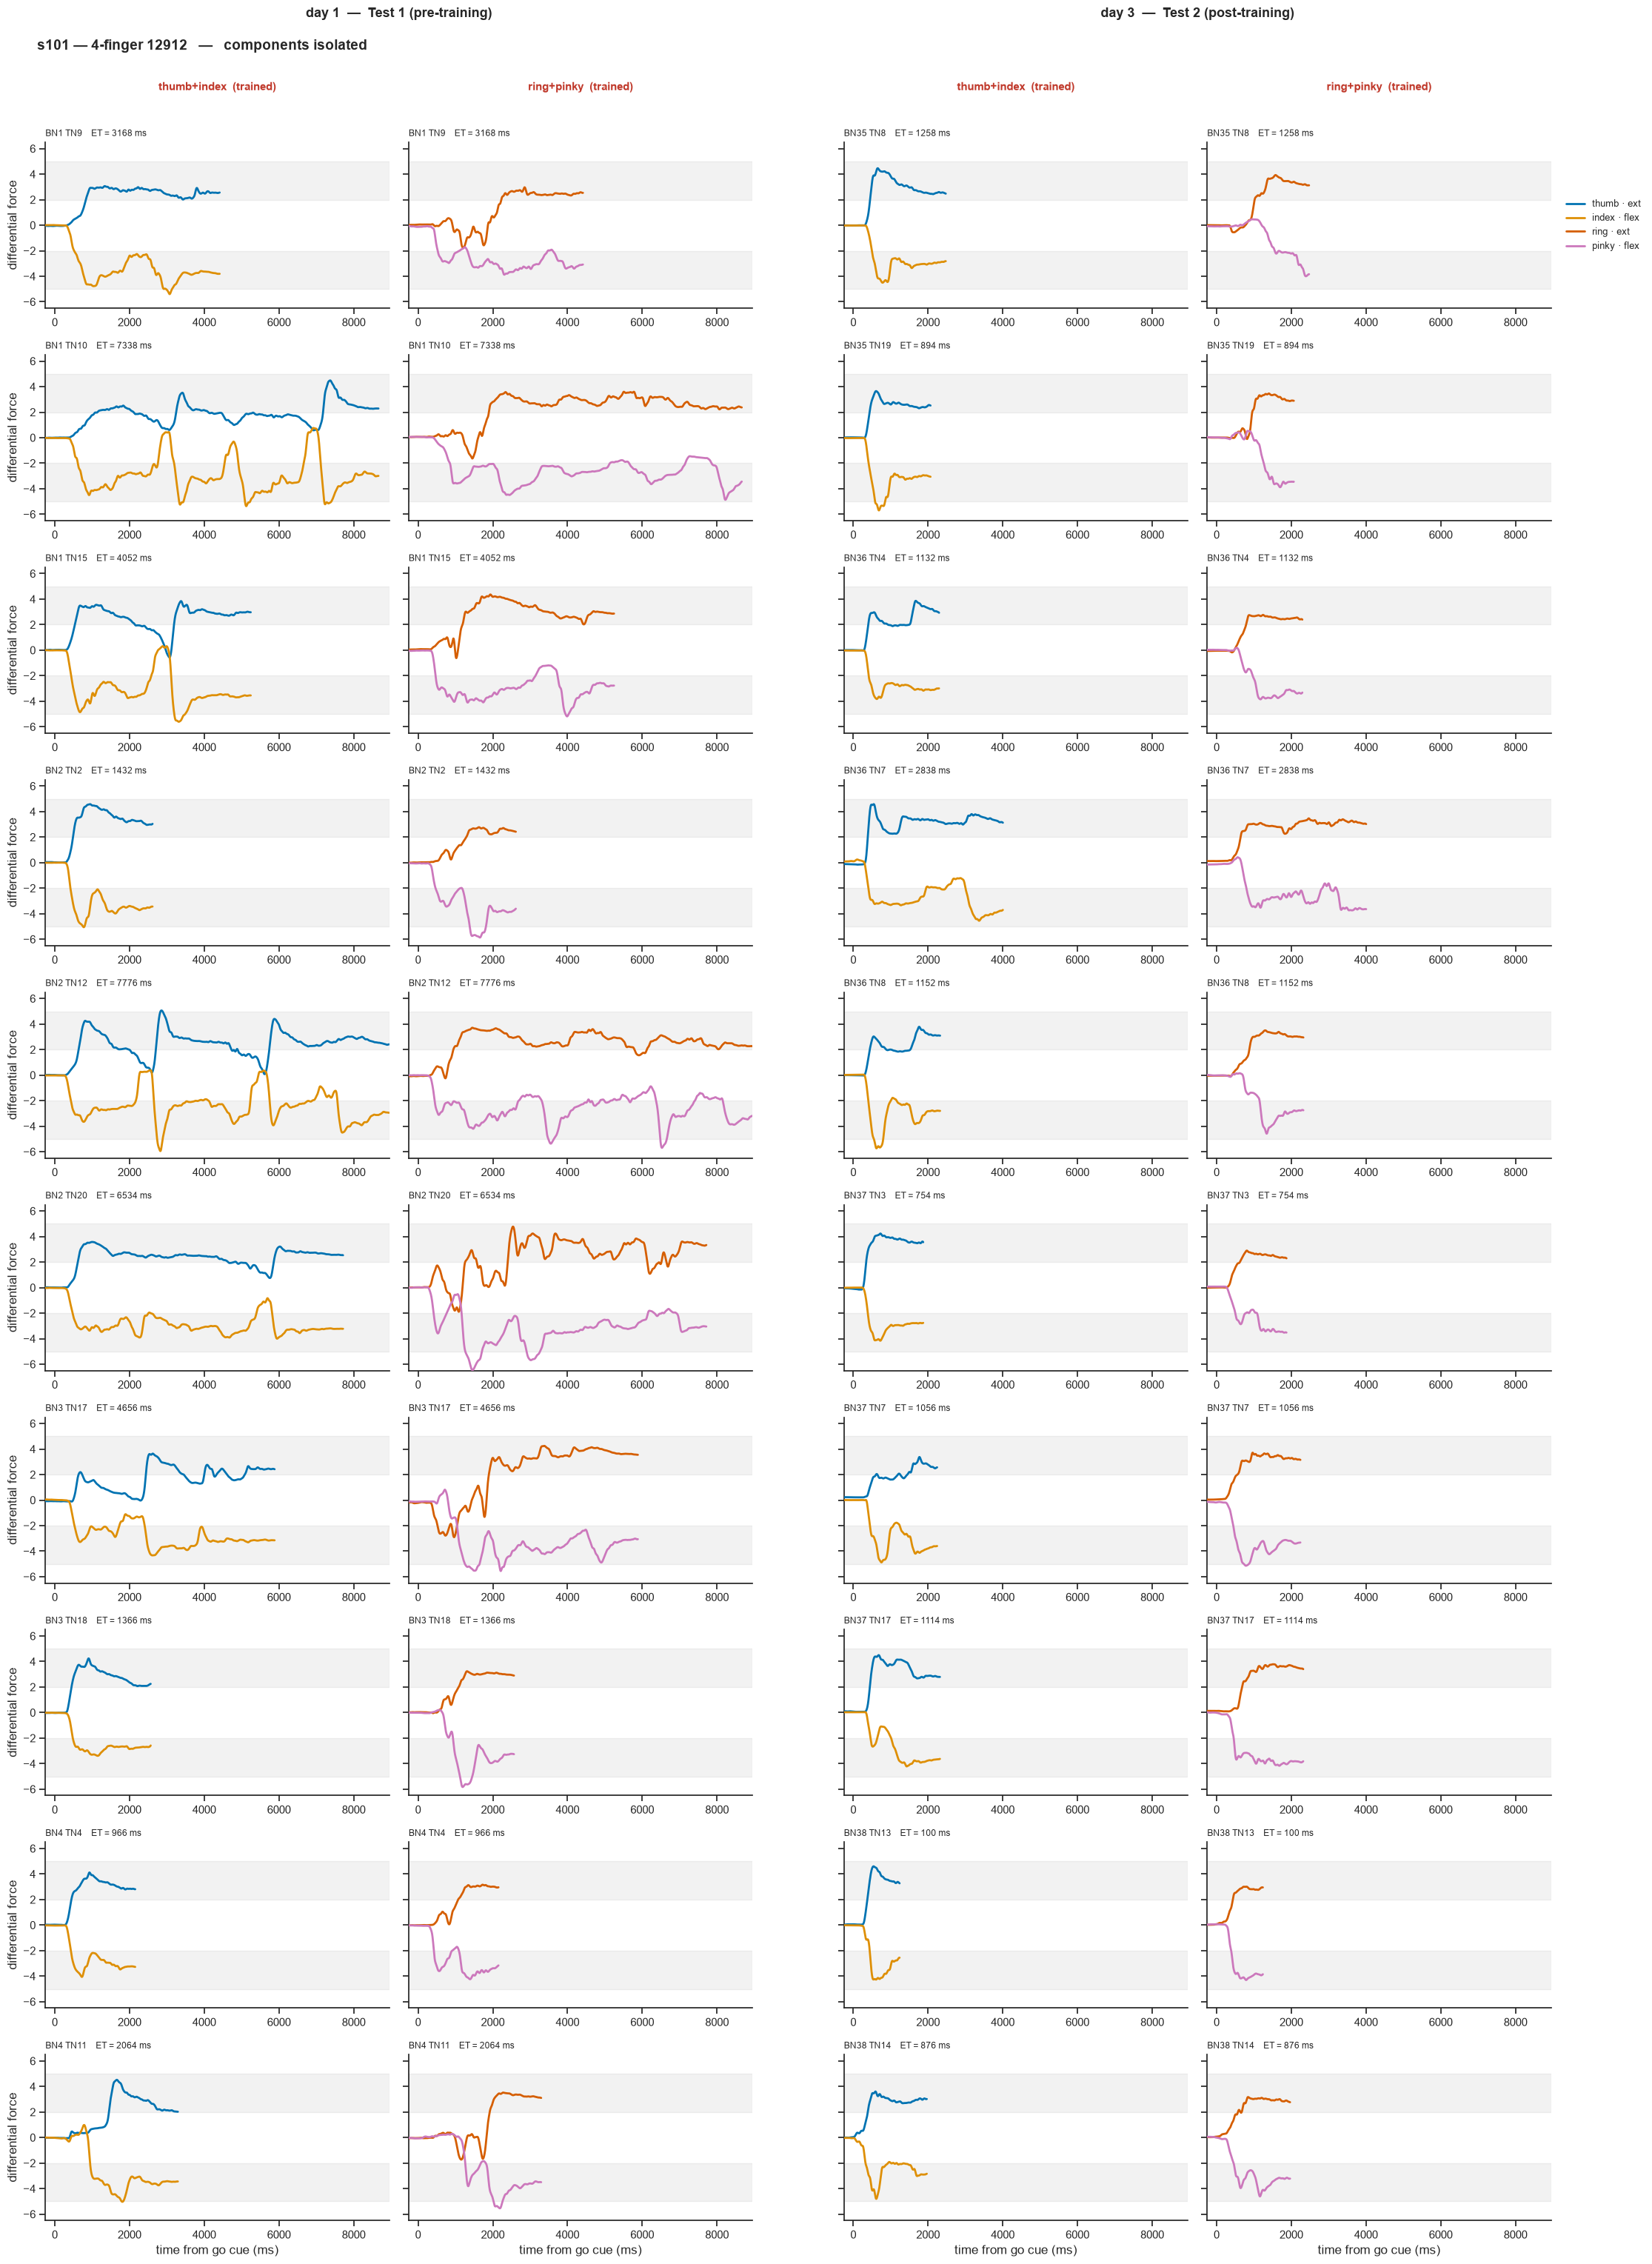

wrote figures/s101/example_trials/force_pairs_12912.png


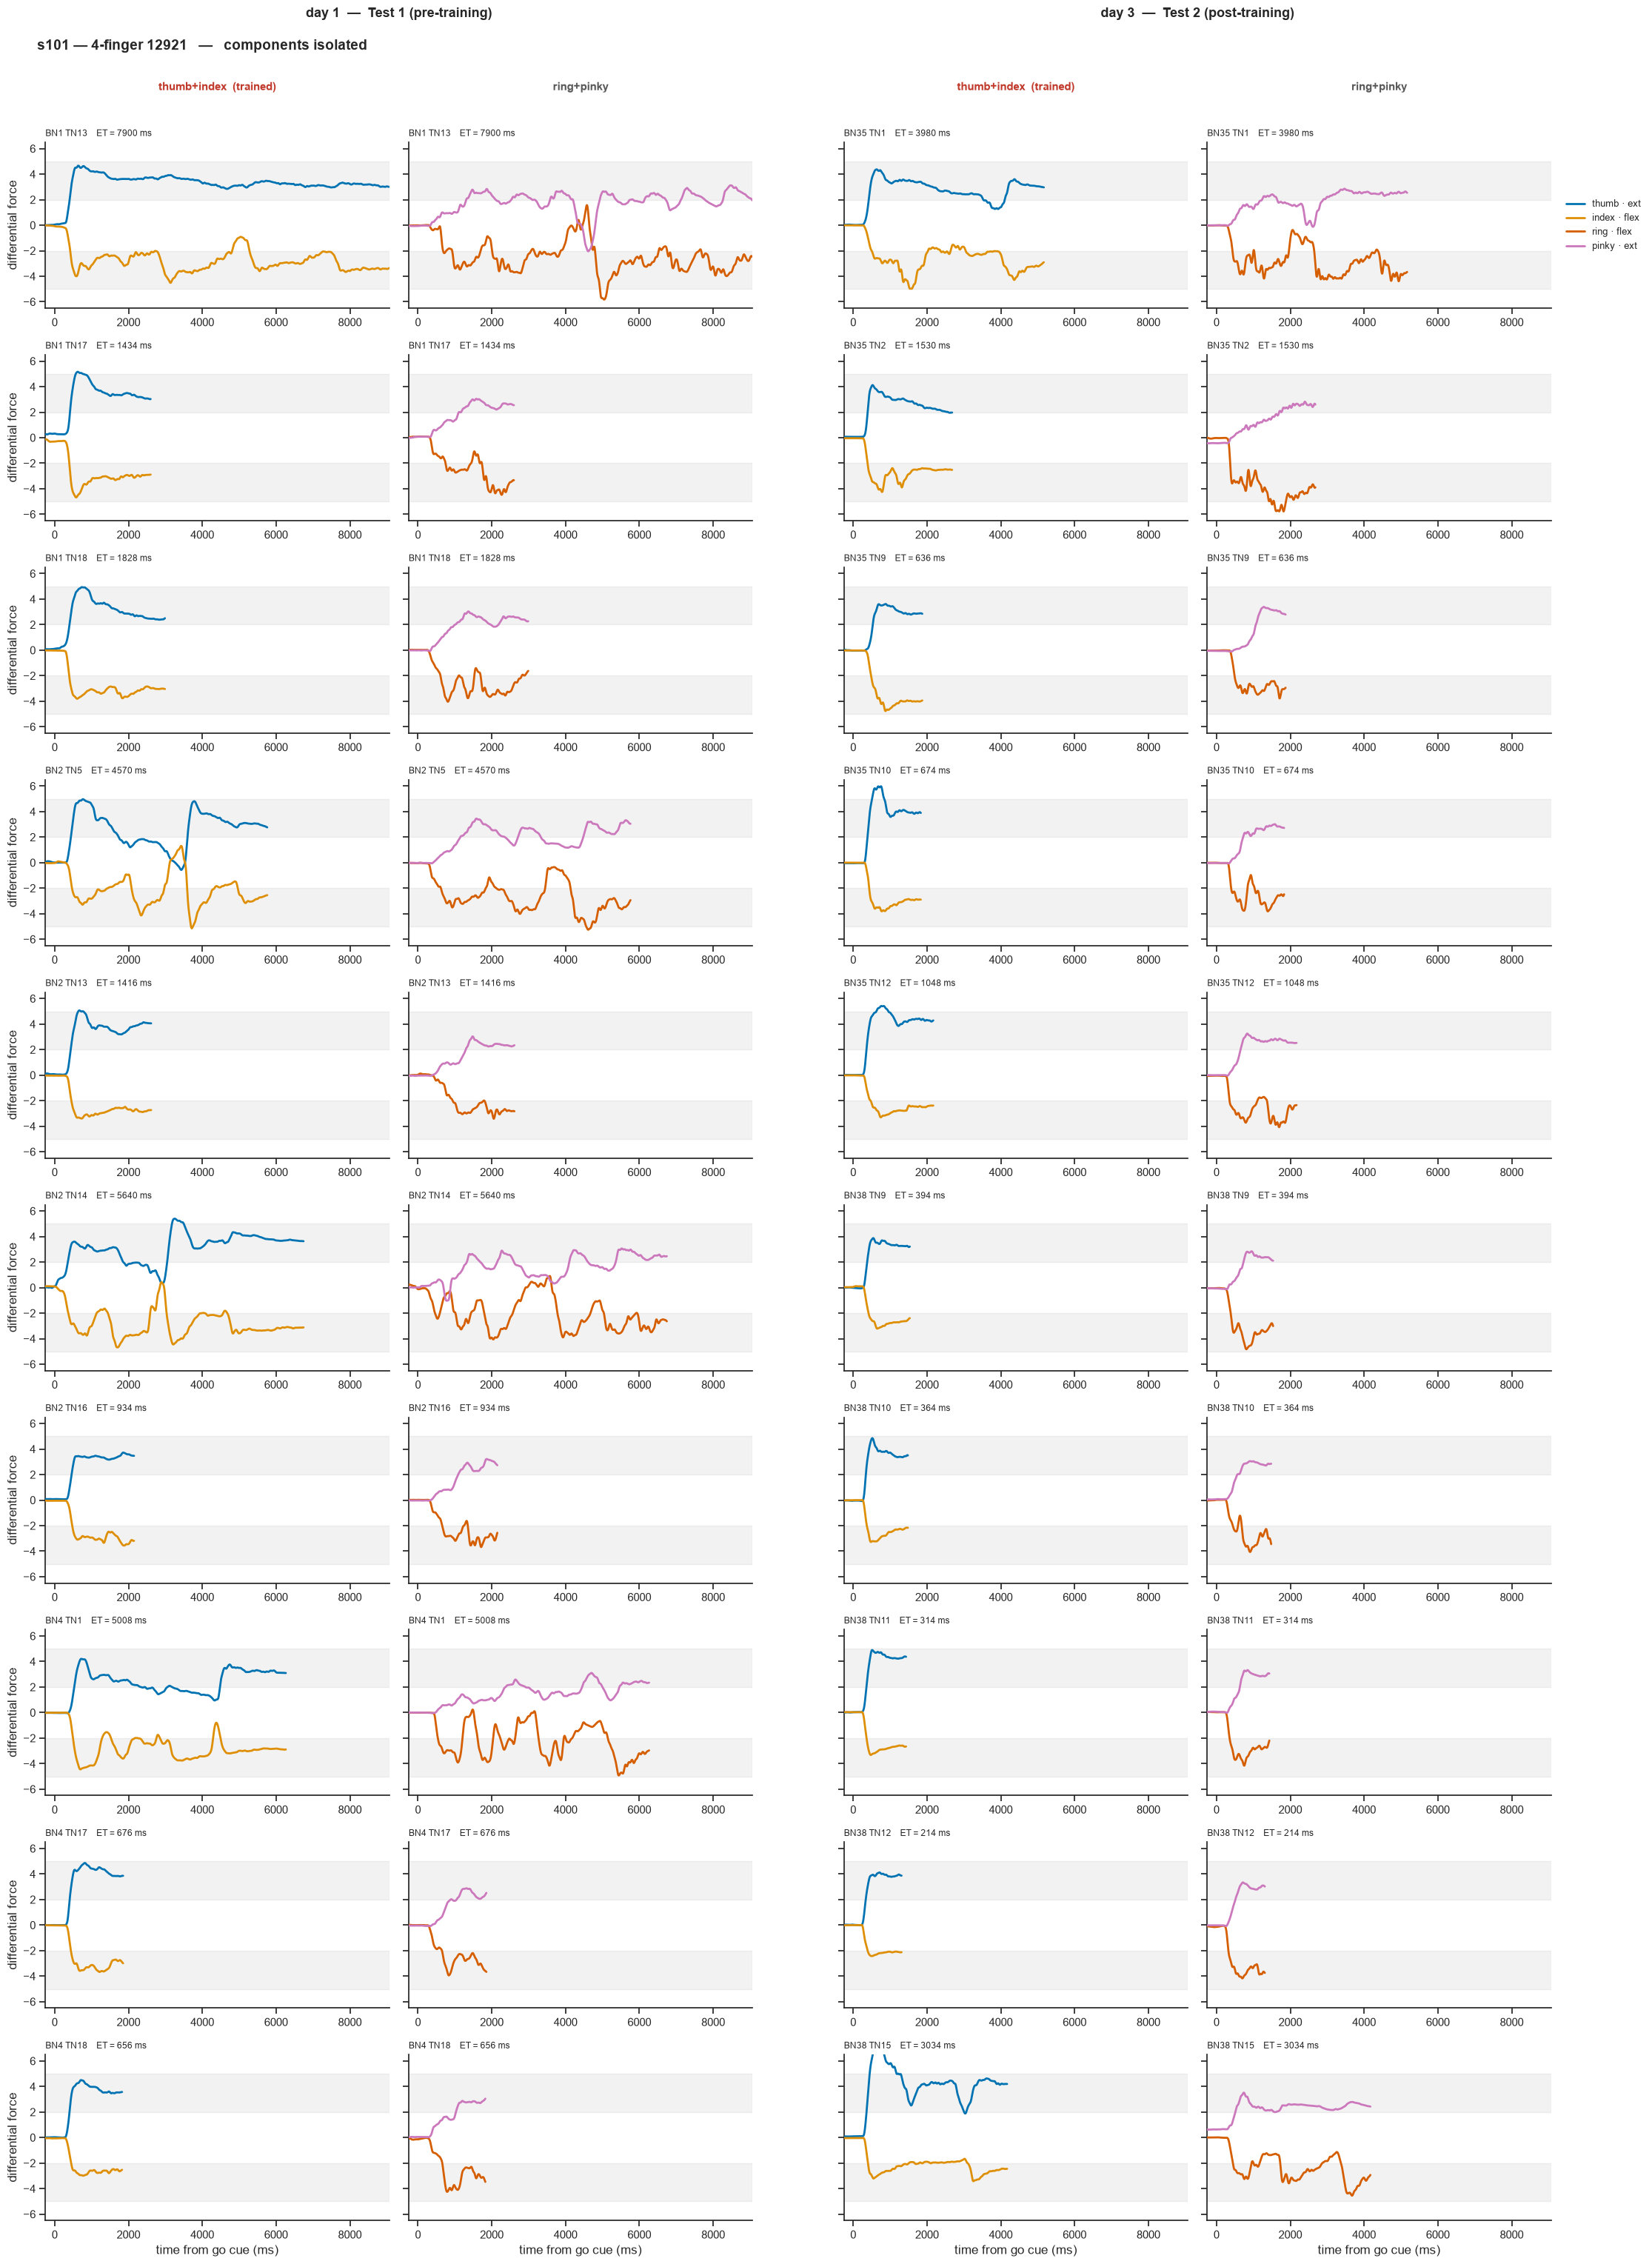

wrote figures/s101/example_trials/force_pairs_12921.png


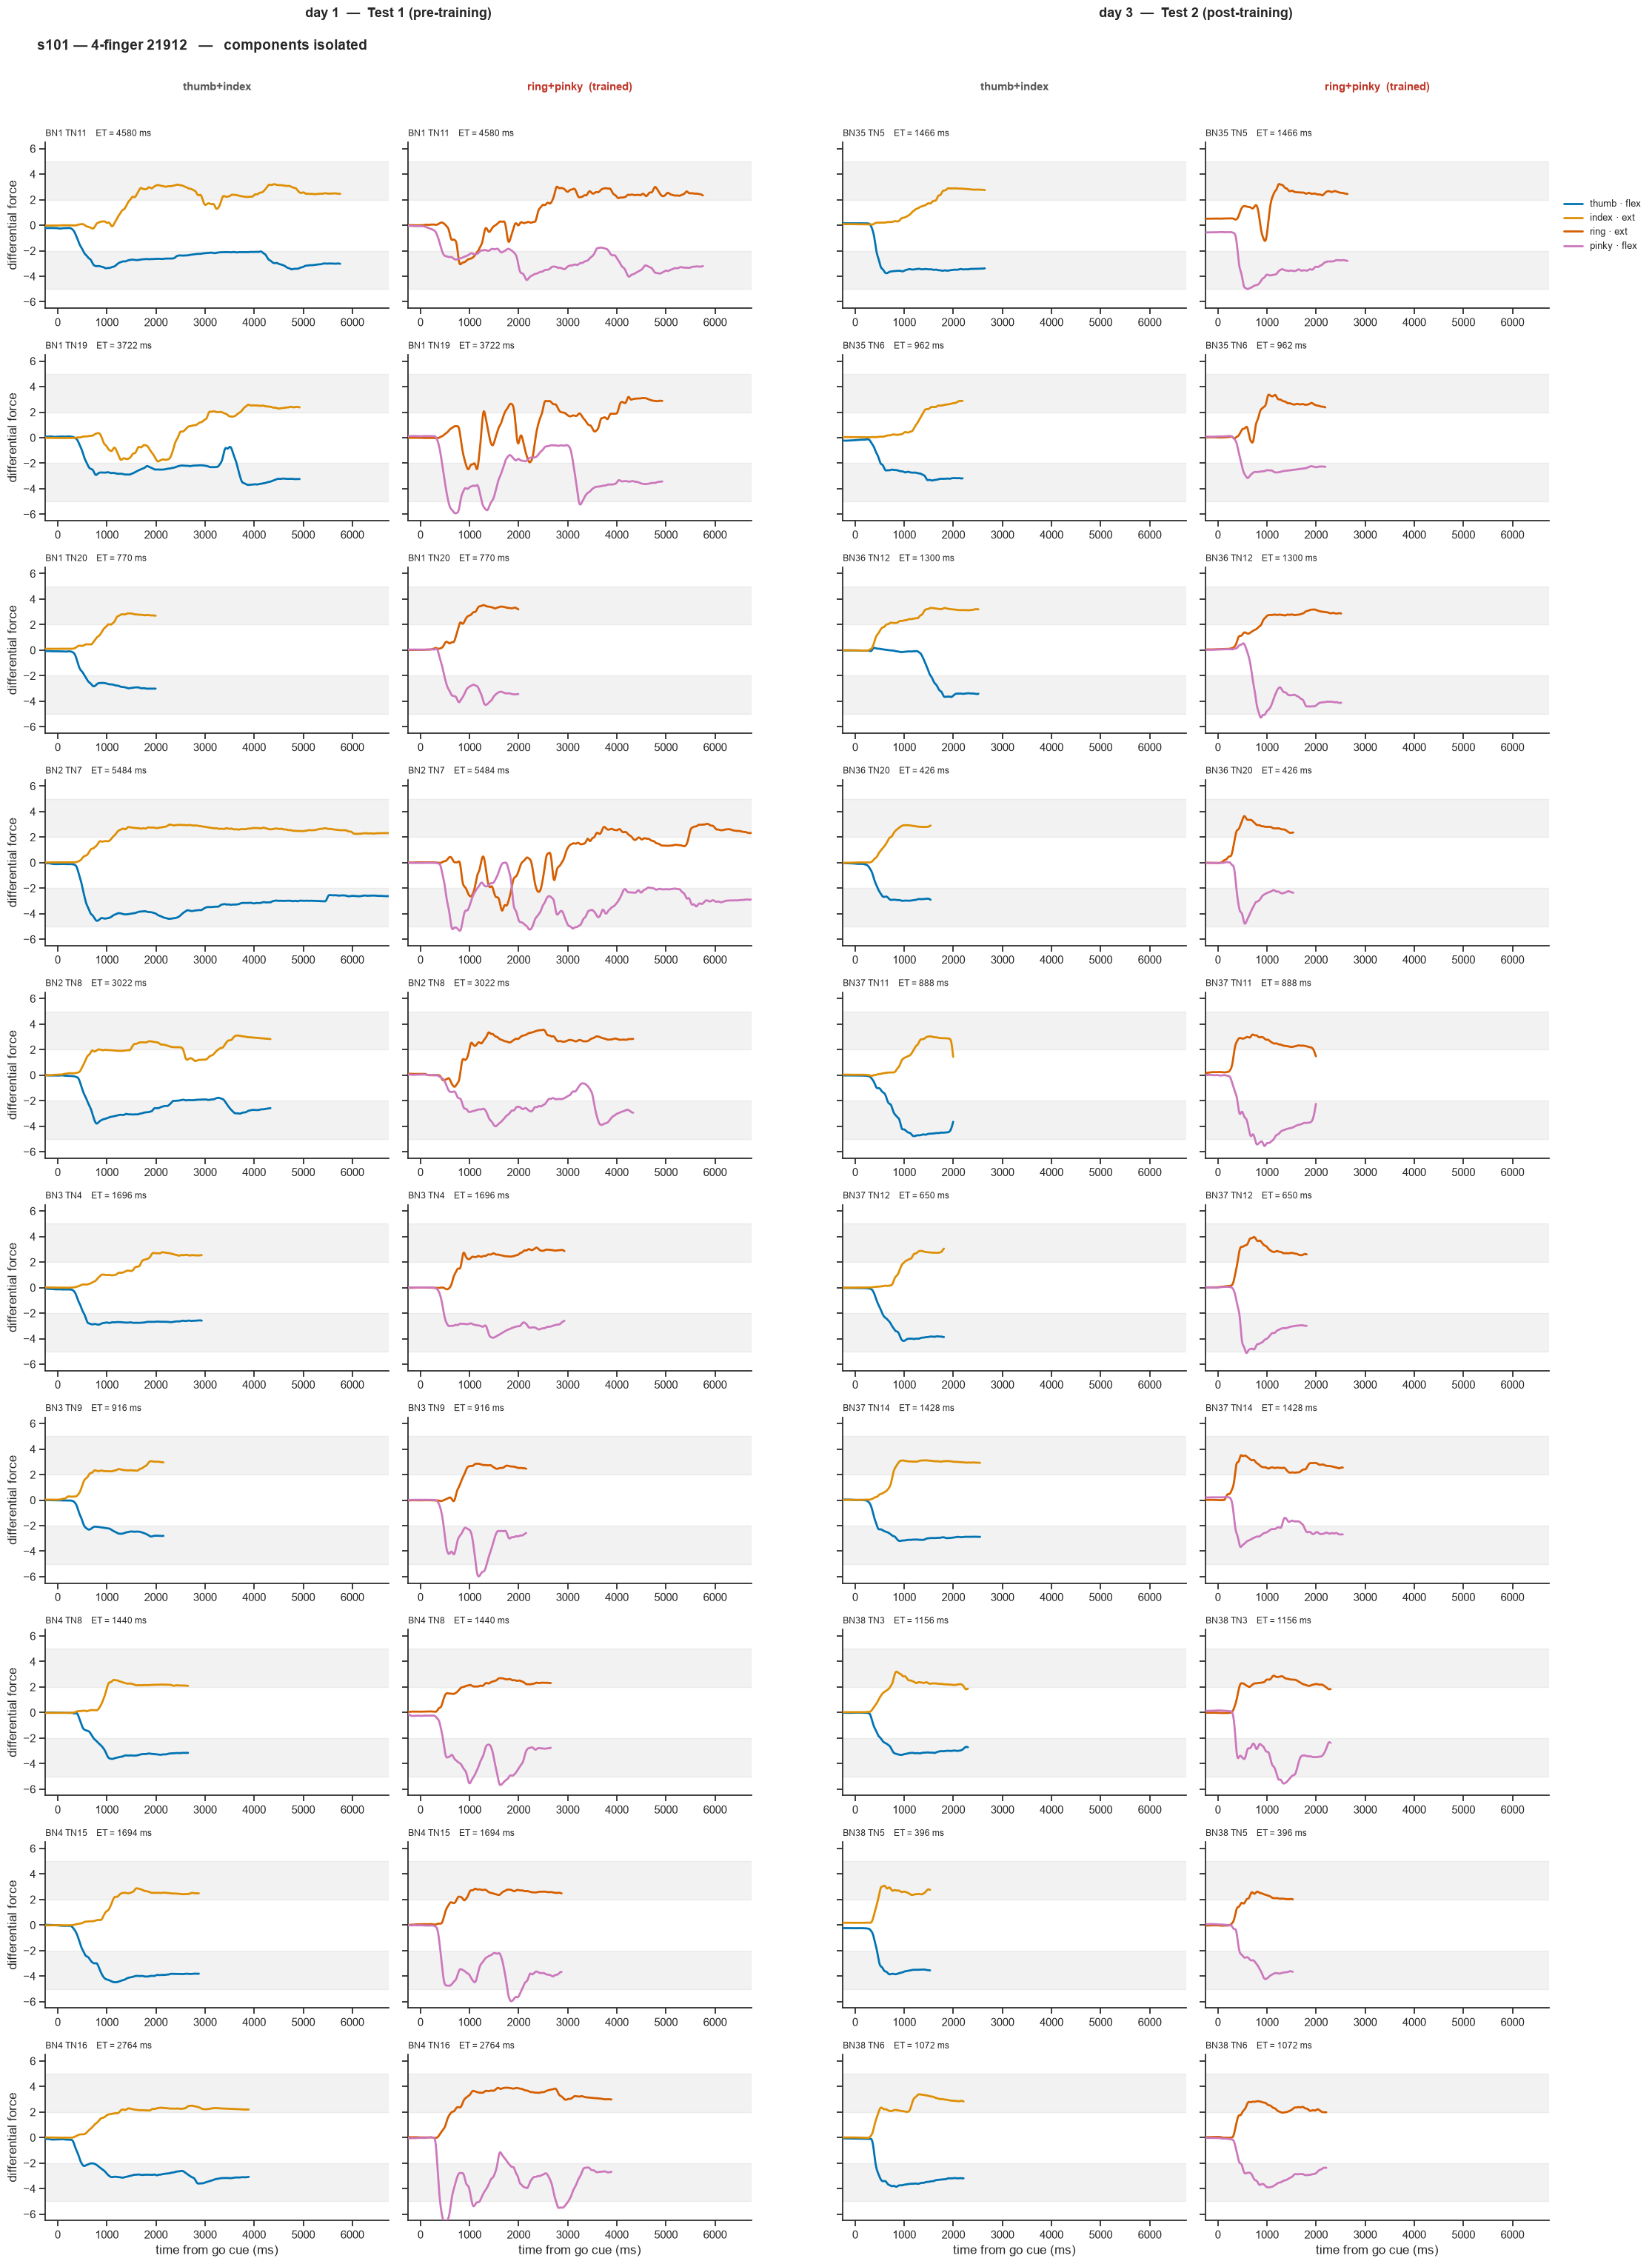

wrote figures/s101/example_trials/force_pairs_21912.png


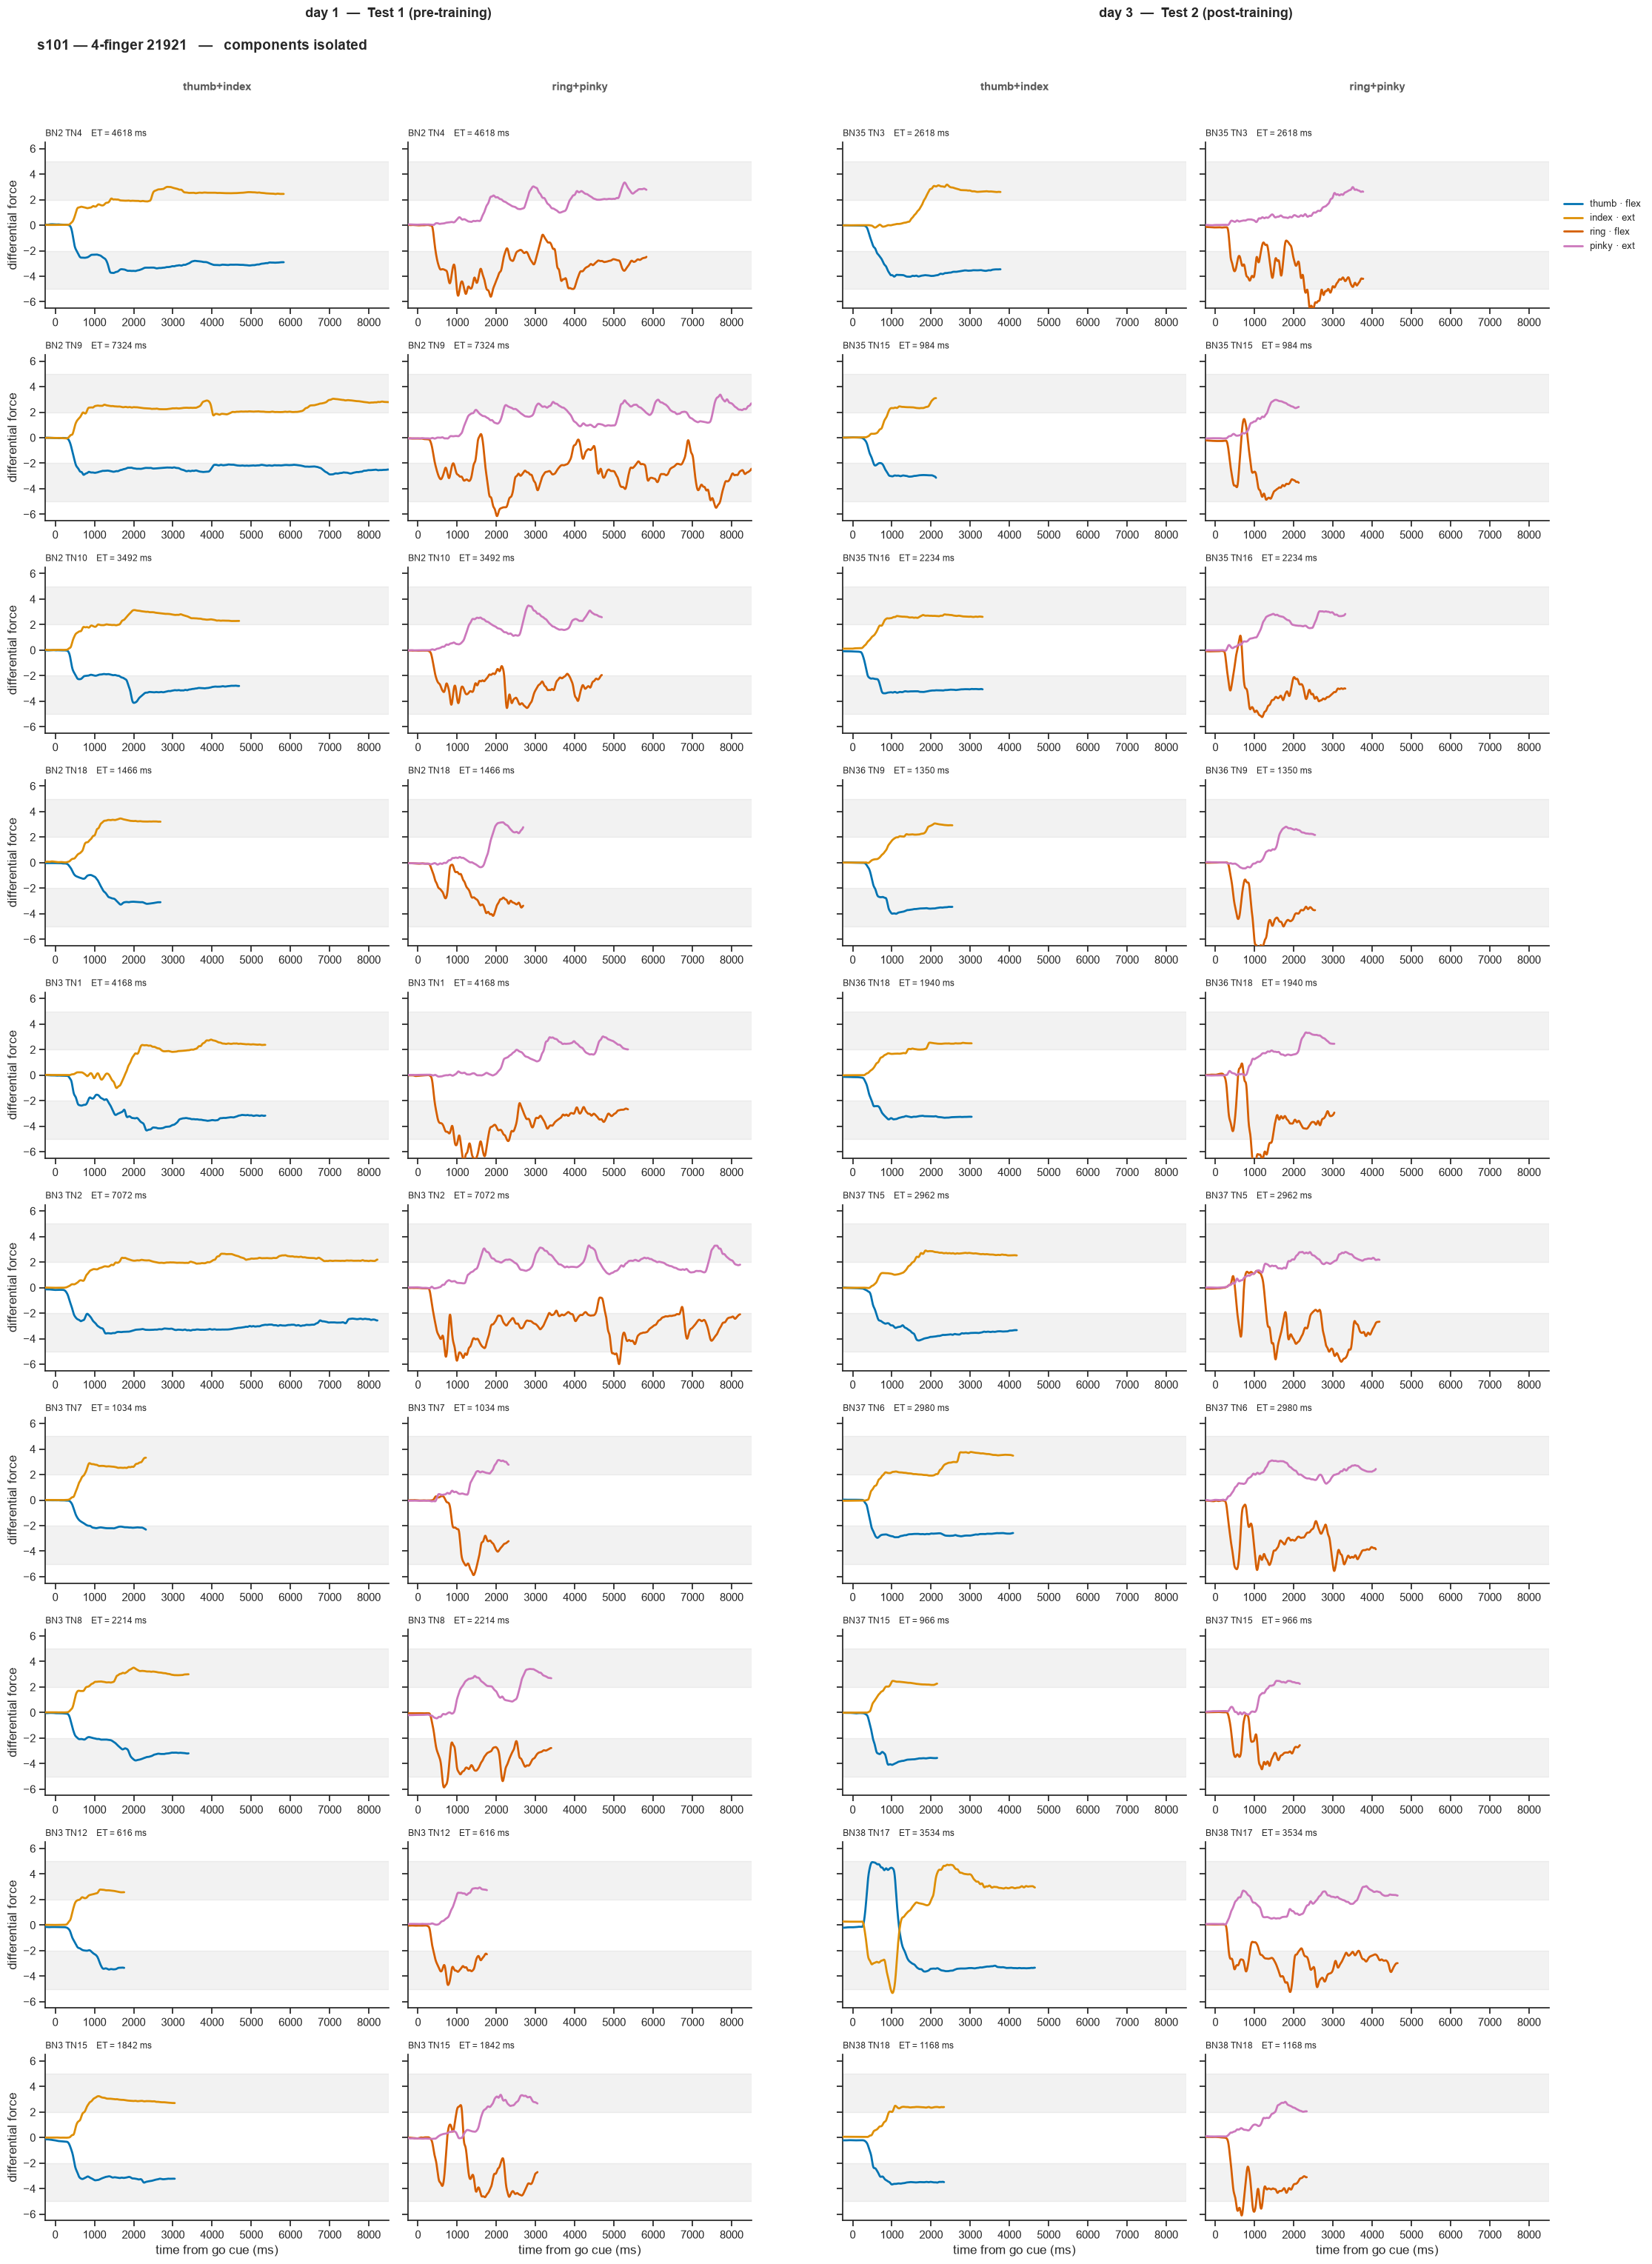

wrote figures/s101/example_trials/force_pairs_21921.png


In [4]:
PAIRS = [(PAIR_A, "thumb+index"), (PAIR_B, "ring+pinky")]
rng = np.random.default_rng(SEED)        # same draw as the full-chord figures above

for chord_id in TESTED:
    chord = str(chord_id)
    picks = {lab: sample(df, chord_id, blocks, N_TRIALS, rng)
             for lab, blocks in SESSIONS}
    nrow = max(len(v) for v in picks.values()) or 1
    ncol = len(SESSIONS) * len(PAIRS)
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.4 * ncol, 3.0 * nrow),
                             sharey=True, squeeze=False)
    xmax = {}                                # per session: failed trials run to 10 s

    for si, (label, _) in enumerate(SESSIONS):
        rows = picks[label]
        for row in range(nrow):
            for pi, (pair, pname) in enumerate(PAIRS):
                ax = axes[row][si * len(PAIRS) + pi]
                if row >= len(rows):
                    ax.set_axis_off()
                    continue
                r = rows[row]
                tr = df[(df.BN == r.BN) & (df.TN == r.TN)].iloc[0]
                rec = REC[(int(r.BN), int(r.TN))]
                t0 = rec.t[rec.state == WAIT_EXEC][0]
                tt = rec.t - t0
                exi = np.where(rec.state == WAIT_EXEC)[0]
                hi = tt[exi[-1]] + 200
                m = (tt >= -250) & (tt <= hi)
                xmax[si] = max(xmax.get(si, 0), hi)

                ax.axhspan(tr.extBotThresh, tr.extTopThresh, color="0.5", alpha=.10, zorder=0)
                ax.axhspan(tr.flexTopThresh, tr.flexBotThresh, color="0.5", alpha=.10, zorder=0)
                for k in pair:
                    ax.plot(tt[m], rec.force[m, k], color=PAL[FINGERS[k]], lw=2, zorder=3)
                ax.set_title(panel_title(r), fontsize=8.5, loc="left")
                mark_unsuccessful(ax, r, fontsize=7.5)
                ax.set_ylim(-6.5, 6.5)
                if si == 0 and pi == 0:
                    ax.set_ylabel("differential force")

    for si in range(len(SESSIONS)):
        for pi in range(len(PAIRS)):
            col = si * len(PAIRS) + pi
            for row in range(nrow):
                if axes[row][col].axison:
                    axes[row][col].set_xlim(-250, xmax.get(si, 1000))
            last = max((r for r in range(nrow) if axes[r][col].axison), default=None)
            if last is not None:
                axes[last][col].set_xlabel("time from go cue (ms)")
            slot = PAIRS[pi][0]
            trained = slot in COMPONENT and all(chord[i] == str(COMPONENT[slot])[i]
                                                for i in slot)
            axes[0][col].annotate(PAIRS[pi][1] + ("  (trained)" if trained else ""),
                                  xy=(.5, 1.30), xycoords="axes fraction", ha="center",
                                  va="bottom", fontsize=10.5, fontweight="bold",
                                  color="#c0392b" if trained else "0.35")

    handles = [Line2D([], [], color=PAL[FINGERS[k]], lw=2,
                      label=f"{FINGERS[k]} · {STATE_OF[chord[k]]}")
               for k in list(PAIR_A) + list(PAIR_B)]
    axes[0][-1].legend(handles=handles, frameon=False, loc="center left",
                       bbox_to_anchor=(1.02, .5), fontsize=9)
    fig.suptitle(f"s{SN} \u2014 4-finger {chord_id}   \u2014   components isolated",
                 fontsize=14, x=.01, ha="left", fontweight="bold", y=1.004)
    sns.despine(fig=fig)
    plt.tight_layout()

    # widen the gap at the session boundary so the two days read as separate blocks
    SESSION_GAP = 0.045                      # <<< figure fraction
    per_session = len(PAIRS)
    for row in range(nrow):
        for col in range(ncol):
            ax = axes[row][col]
            if not ax.axison:
                continue
            shift = -SESSION_GAP / 2 if col < per_session else SESSION_GAP / 2
            b = ax.get_position()
            ax.set_position([b.x0 + shift, b.y0, b.width, b.height])

    # session headers, centred over each pair of columns
    fig.canvas.draw()
    for si, (label, _) in enumerate(SESSIONS):
        b0 = axes[0][si * len(PAIRS)].get_position()
        b1 = axes[0][si * len(PAIRS) + len(PAIRS) - 1].get_position()
        fig.text((b0.x0 + b1.x1) / 2, b0.y1 + .055, session_label(label, picks[label]),
                 ha="center", va="bottom", fontsize=13, fontweight="bold")

    plt.savefig(EX_DIR / f"force_pairs_{chord_id}.png", dpi=175, bbox_inches="tight",
                facecolor="white")
    plt.show()
    print(f"wrote {EX_DIR.relative_to(ROOT)}/force_pairs_{chord_id}.png")

## Within-latency of the trained components, day 1 vs day 3

One panel per 4-finger chord that contains at least one trained component. Within a panel,
each component gets its day 1 and day 3 boxes side by side. `21921` is excluded — it
contains neither component, so it has no within latency to report.

The dashed line is that component's own median within latency on its 2-finger training
trials in the same session: the synchrony it reaches when produced on its own, which is the
benchmark the embedded version would have to match.

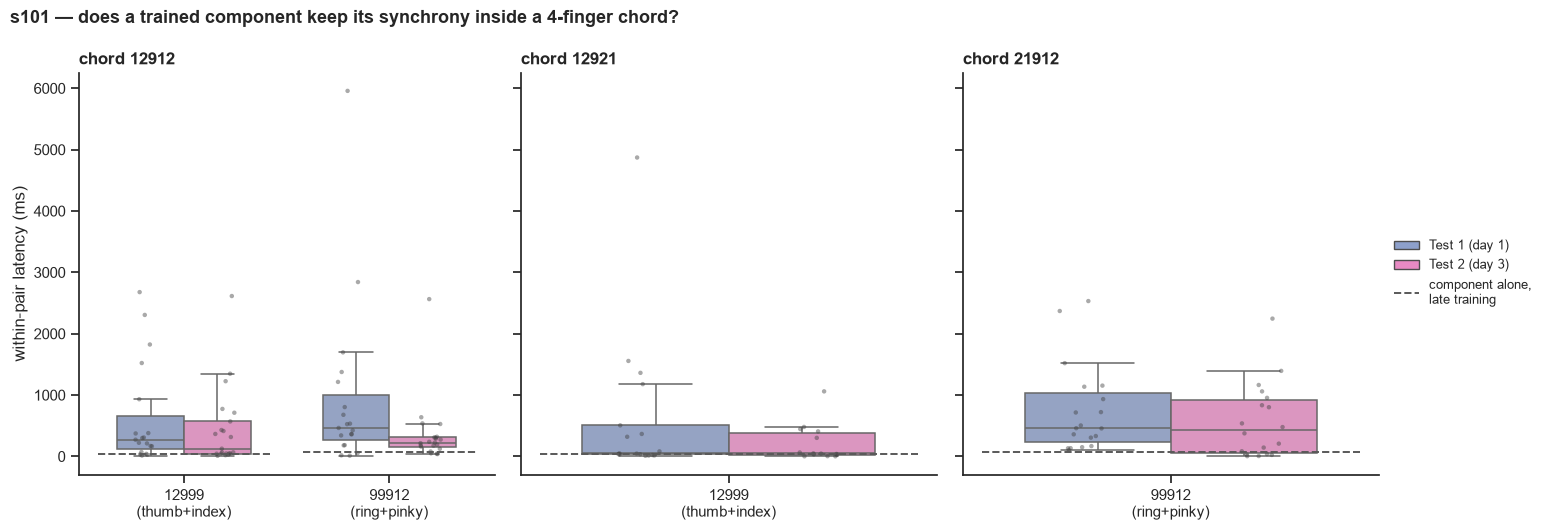

                                             count  median   mean
chordID component            test                                
12912   12999\n(thumb+index) Test 1 (day 1)     19   272.0  623.9
                             Test 2 (day 3)     21   126.0  443.7
        99912\n(ring+pinky)  Test 1 (day 1)     19   464.0  948.9
                             Test 2 (day 3)     21   226.0  356.8
12921   12999\n(thumb+index) Test 1 (day 1)     17    50.0  618.1
                             Test 2 (day 3)     14    48.0  211.6
21912   99912\n(ring+pinky)  Test 1 (day 1)     19   460.0  746.7
                             Test 2 (day 3)     18   427.0  576.9


In [5]:
four = arr[arr.n_active == 4].copy()
long = []
for _, r in four[four.test != "training"].iterrows():
    for pair, tag in [(PAIR_A, "A"), (PAIR_B, "B")]:
        if r[f"{tag}_trained"]:
            long.append(dict(chordID=r.chordID, test=r.test,
                             component=f"{COMPONENT[pair]}\n({FINGERS[pair[0]]}+{FINGERS[pair[1]]})",
                             component_id=COMPONENT[pair], within=r[f"within_{tag}"]))
long = pd.DataFrame(long)

panels = [c for c in TESTED if (long.chordID == c).any()]
fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.4),
                         sharey=True, squeeze=False)
HUE = {"Test 1 (day 1)": "#8da0cb", "Test 2 (day 3)": "#e78ac3"}

for ax, cid in zip(axes[0], panels):
    d = long[long.chordID == cid]
    order = sorted(d.component.unique())
    sns.boxplot(data=d, x="component", y="within", hue="test", order=order,
                hue_order=list(HUE), palette=HUE, width=.65, fliersize=0,
                linewidth=1.1, ax=ax)
    sns.stripplot(data=d, x="component", y="within", hue="test", order=order,
                  hue_order=list(HUE), dodge=True, palette={k: "0.25" for k in HUE}, size=3.2,
                  alpha=.45, legend=False, ax=ax)
    # benchmark: the component alone, on its own training trials in the same session
    for i, comp in enumerate(order):
        cid_comp = d[d.component == comp].component_id.iloc[0]
        col = "within_A" if COMPONENT.get(PAIR_A) == cid_comp else "within_B"
        ref = arr[(arr.chordID == cid_comp) & (arr.BN.isin(TRAIN_LATE))][col].dropna()
        if len(ref):
            ax.hlines(ref.median(), i - .42, i + .42, color="0.35", ls="--", lw=1.4, zorder=5)
    ax.set_title(f"chord {cid}", fontsize=12, loc="left", fontweight="bold")
    ax.set_xlabel(""); ax.set_ylabel("within-pair latency (ms)")
    ax.legend_.remove() if ax.legend_ else None

axes[0][0].set_ylabel("within-pair latency (ms)")
h = [plt.Rectangle((0, 0), 1, 1, fc=v, ec="0.3") for v in HUE.values()]
h.append(Line2D([], [], color="0.35", ls="--", lw=1.4))
axes[0][-1].legend(h, list(HUE) + ["component alone,\nlate training"],
                   frameon=False, loc="center left", bbox_to_anchor=(1.01, .5), fontsize=9)
fig.suptitle(f"s{SN} — does a trained component keep its synchrony inside a 4-finger chord?",
             fontsize=13, x=.01, ha="left", fontweight="bold")
sns.despine(fig=fig)
plt.tight_layout()
plt.savefig(WL_DIR / "08_within_latency.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(long.groupby(["chordID", "component", "test"])["within"]
      .agg(["count", "median", "mean"]).round(1).to_string())

## Statistics

In [6]:
def perm(a, b, n=20000):
    obs = a.mean() - b.mean()
    pool = np.concatenate([a, b]); na = len(a)
    null = [np.mean(s[:na]) - np.mean(s[na:]) for s in (rng.permutation(pool) for _ in range(n))]
    return obs, np.mean(np.abs(null) >= abs(obs))

print("Within-latency of each trained component inside each chord, day 1 vs day 3")
print("=" * 78)
for cid in panels:
    for comp in sorted(long[long.chordID == cid].component.unique()):
        d = long[(long.chordID == cid) & (long.component == comp)]
        a = d[d.test == "Test 1 (day 1)"]["within"].to_numpy()
        b = d[d.test == "Test 2 (day 3)"]["within"].to_numpy()
        if len(a) < 3 or len(b) < 3:
            continue
        o, p = perm(a, b)
        print(f"  chord {cid}  {comp.splitlines()[0]:<6} "
              f"{a.mean():6.0f} -> {b.mean():6.0f} ms   delta = {o:+6.0f}   "
              f"p = {p:.4f} {'*' if p < .05 else 'ns'}   (n = {len(a)}, {len(b)})")

print("\nInternal control: trained vs untrained pair, measured on the SAME trials")
print("=" * 78)
print("  (same trial, same ET, so a difference cannot come from the trial getting shorter)")
for cid in TESTED:
    d = four[(four.chordID == cid) & (four.test != "training")]
    for test in ["Test 1 (day 1)", "Test 2 (day 3)"]:
        dd = d[d.test == test]
        if dd.empty:
            continue
        tr_vals, un_vals = [], []
        for _, r in dd.iterrows():
            for tag in ("A", "B"):
                (tr_vals if r[f"{tag}_trained"] else un_vals).append(r[f"within_{tag}"])
        tr_vals, un_vals = np.array(tr_vals), np.array(un_vals)
        if len(tr_vals) < 3 or len(un_vals) < 3:
            note = "all pairs trained" if not len(un_vals) else "no trained pair"
            print(f"  {cid} {test}: {note}")
            continue
        o, p = perm(un_vals, tr_vals)
        print(f"  {cid} {test}: trained {tr_vals.mean():5.0f} ms vs untrained "
              f"{un_vals.mean():5.0f} ms   diff = {o:+5.0f}   p = {p:.4f} "
              f"{'*' if p < .05 else 'ns'}")

Within-latency of each trained component inside each chord, day 1 vs day 3
  chord 12912  12999     624 ->    444 ms   delta =   +180   p = 0.4456 ns   (n = 19, 21)
  chord 12912  99912     949 ->    357 ms   delta =   +592   p = 0.0576 ns   (n = 19, 21)


  chord 12921  12999     618 ->    212 ms   delta =   +407   p = 0.2472 ns   (n = 17, 14)


  chord 21912  99912     747 ->    577 ms   delta =   +170   p = 0.4568 ns   (n = 19, 18)

Internal control: trained vs untrained pair, measured on the SAME trials
  (same trial, same ET, so a difference cannot come from the trial getting shorter)
  12912 Test 1 (day 1): all pairs trained
  12912 Test 2 (day 3): all pairs trained
  12921 Test 1 (day 1): trained   618 ms vs untrained   403 ms   diff =  -216   p = 0.6438 ns
  12921 Test 2 (day 3): trained   212 ms vs untrained   479 ms   diff =  +267   p = 0.0594 ns


  21912 Test 1 (day 1): trained   747 ms vs untrained   895 ms   diff =  +148   p = 0.5593 ns


  21912 Test 2 (day 3): trained   577 ms vs untrained   383 ms   diff =  -194   p = 0.2589 ns
  21921 Test 1 (day 1): no trained pair
  21921 Test 2 (day 3): no trained pair
